# 07 Required support: from the mandate's shadow price to a required credit rate

**Purpose.** This notebook turns the shadow price of the nuclear capacity mandate into the
support a program needs and into the investment tax credit (ITC) rate that would deliver it. The
*shadow price* (also called the dual) is the marginal system cost of one more MW of required
nuclear capacity in a solve year; the production runs remove every nuclear credit, so the shadow
price is the total support the mandated technology needs. The notebook reads the 49 base-world
runs: 18 SMR-program runs and 1 equality copy (`smr100`), 6 large-reactor comparators at P50
(`smr100` casefile), 12 large-reactor comparators at P5 and P95 (`step4` casefile) and 12 SMR
runs at P25 and P75 (`ratedesign` casefile). It writes the run inventory (Table 1), the Fig. 2a
target panel, the system-cost and NPV exhibits (Supplementary Figs. 8 and 9), the required credit
rate (Supplementary Fig. 10, Supplementary Table 2), the fiscal comparison (Supplementary Table
11), the production-credit check (Supplementary Table 12), the large-over-SMR ratio
(Supplementary Table 15) and a check of the hand-read numbers of Supplementary Note 6. Later
notebooks read its `t` exports: 08 (`t04`), 09 (`t09`), 10 (`t01`, `t08`, `t09`, `t12`),
11 (`t09`), 13a/13b (`t04`, `t08`) and 14 (`t08`, `t09`, `t12`).

**Inputs.**
- `results/extracts/{smr100,step4,ratedesign}/*.parquet` (notebook 05_extract_reeds_outputs):
  `systemcost`, `z_rep`, `raw_inv_cost`, `raw_op_cost`, `objfn_raw`, `tax_expenditure_itc`,
  `pvf_onm`, `cost_cap`, `cost_cap_fin_mult`, `cost_cap_fin_mult_noITC`, `cap_new_ann`, `cap`,
  `nuclear_cap_price`, `reduced_cost`.
- `results/exports/06a/step3_checks/{duals_by_year,overbuild_by_case}.csv`,
  `results/exports/06a/step4_checks/{duals_by_year,overbuild_by_case}.csv`
  (notebook 06a_run_tables_core) and `results/exports/06b/rate_design_checks/duals_by_year.csv`
  (notebook 06b_run_tables_rate_design).
- Casefiles `cases_nuclearlearning_{smr100,step4,ratedesign}.csv` at the repository root.
- ReEDS inputs of this fork: `inputs/nuclear_learning/nuclear_cap_trajectory_*.csv`,
  `inputs/financials/{deflator, financials_sys_ATB2024, inflation_default,
  depreciation_schedules_default, construction_schedules_mc, financials_tech_mc_*,
  incentives_obbba, incentives_obbba_nonuclearitc}.csv`, `inputs/zones/z90/hierarchy.csv`.

**Outputs.** `results/exports/07/`: `t01_case_inventory`, `t02_slack_years`, `t03_dual_summary`,
`t04_bridge_metrics`, `t05_systemcost_by_case`, `t06_cost_deltas`, `t07_system_npv`,
`t08_rental_transfer`, `t09_required_itc`, `t10_itc_outlay`, `t11_myopia_wedge`,
`t12_fiscal_comparison`, `t13_flat_grant`, `t14_itc_resolution`, `t15_large_ratio`,
`t19_commitment_itc`, `t20_haircut_range`, `t23_ptc_equivalence`, `Table1_deployment_schedules`,
`sn6_uniform_rate_check`,
`sn6_uniform_rate_by_year` (CSV); the panels `f01b_new_nuclear_trajectories.png` (Fig. 2a
source), `f08`, `f09`, `f10`, `f11`, `f13` (PNG). `results/figures/si/`:
`SF08_cost_anatomy.png`, `SF09_spread_and_npv.png`, `SF10_required_credit_rate.png`.

**Paper items.** Table 1 (`Table1_deployment_schedules`, from `t01`), Fig. 2a (panel), Supplementary Figs. 8, 9, 10;
Supplementary Tables 2 (`t09`), 11 (`t10`, `t12`, `t13`, `t14`, `t20`), 12 (`t23`), 15 (`t15`);
Supplementary Note 6 (method, and the check in the last section).

**Runtime.** About 45 seconds on this machine (extracts only; no h5 file is opened).

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4)

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.


{'python': '3.12.3',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'threads': 4,
 'threadpoolctl': True,
 'env_set': {'OMP_NUM_THREADS': '4',
  'MKL_NUM_THREADS': '4',
  'OPENBLAS_NUM_THREADS': '4',
  'NUMEXPR_NUM_THREADS': '4',
  'NUMBA_NUM_THREADS': '4'},
 'matplotlib': '3.8.4',
 'seed_note': None}

## 1. Runs, reader and conventions

The next cell defines the 49 runs and a reader for their outputs. Each run is one *target
trajectory* (a national path of mandated nuclear capacity from one published source, called a
schedule in the code: `eia`, `aj`, `iaea`, `mck`, `cop28`, `eo`, ordered by 2050 ambition) in one
*cost sample* (a joint Monte Carlo draw of the cost world, at the P5, P25, P50, P75 or P95
percentile of the discounted program cost; `p05` ... `p95` in the code). The SMR program
(`smr100_*`) forces the schedule on new SMR capacity only (the *additions basis*). The
large-reactor comparator (`large100_*`) forces the same schedule on all large-reactor capacity,
the existing fleet included (the *fleet-inclusive basis*).

The reader `load(case, key)` returns one report table of one run from the parquet extracts of
notebook 05, with the same columns and row order as the `outputs.h5` table. ReEDS drops a report
table whose values are all zero, so a missing table means zero, not lost data.

**Units.** ReEDS reports dollars of 2004. The exports keep 2004 dollars (rates, $/MW) or 2024
dollars (columns named `_2024`), exactly as the source analysis wrote them. Figures show 2025
dollars at the point of display (`ps.to2025(2024)`).

In [2]:
import json
import shutil

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)

EXPORTS = paths.exports("07")
FIGURES = EXPORTS                      # the source panels live beside the tables
REPO = paths.REPO
INPUTS = paths.reeds_inputs()

# ---- case matrix ----------------------------------------------------------------
cases_csv = pd.read_csv(paths.casefile("smr100"), index_col=0)
CASES = [c for c in cases_csv.columns if c != "Default Value"]
assert len(CASES) == 25, f"the smr100 casefile holds 18 SMR runs, 6 large P50 runs and 1 equality copy: {CASES}"

# The 12 large100 percentile cases complete the large-reactor arm to P5/P50/P95.
# They are base-world runs of the step4 casefile; the 108 market-sensitivity runs are notebook 08's.
cases_csv4 = pd.read_csv(paths.casefile("step4"), index_col=0)
CASES4_LARGE = [c for c in cases_csv4.columns if c.startswith("large100_")]
assert len(CASES4_LARGE) == 12, f"step4 holds 12 large100 P5/P95 base-world runs: {CASES4_LARGE}"
CASES = CASES + CASES4_LARGE
assert len(CASES) == 37, len(CASES)
CASES_PROD = list(CASES)      # the 37 production cases

# The 12 smr100 P25/P75 anchors of the ratedesign casefile: mandate on, learning off,
# no nuclear ITC, standard horizon (the smr100 column pattern).
cases_rd = pd.read_csv(paths.casefile("ratedesign"), index_col=0)
CASES_RD_ANCHOR = [c for c in cases_rd.columns if c.startswith("smr100_")]
assert len(CASES_RD_ANCHOR) == 12, f"ratedesign holds 12 smr100 P25/P75 anchors: {CASES_RD_ANCHOR}"
assert all(c.split("_")[2] in ("p25", "p75") for c in CASES_RD_ANCHOR)
CASES = CASES + CASES_RD_ANCHOR
assert len(CASES) == 49, len(CASES)
DESIGN = {c: ("anchor-densification" if c in CASES_RD_ANCHOR else "production") for c in CASES}

def sw(case, name):
    """Read one switch value for one case. An empty cell uses the default value."""
    csv_ = (cases_csv4 if case in CASES4_LARGE
            else cases_rd if case in CASES_RD_ANCHOR else cases_csv)
    v = csv_.loc[name, case]
    if pd.isna(v) or str(v).strip() == "":
        v = csv_.loc[name, "Default Value"]
    return str(v).strip()

META = {}
for c in CASES:
    ts = sw(c, "GSw_NuclearCapMandateTechScen")
    META[c] = dict(
        scen=sw(c, "GSw_NuclearCapMandateScen"),
        mode=int(float(sw(c, "GSw_NuclearCapMandate"))),
        techscen=ts,
        mandated_tech={"smr": "nuclear-smr", "large": "nuclear"}[ts],
    )
SMR_CASES = [c for c in CASES if META[c]["techscen"] == "smr"]
LARGE_CASES = [c for c in CASES if META[c]["techscen"] == "large"]
SCHEDULES = ["eia", "aj", "iaea", "mck", "cop28", "eo"]      # ordered by 2050 ambition
SCHED_GW = {"eia": 117.3, "aj": 134.0, "iaea": 172.3, "mck": 200.0,
            "cop28": 300.0, "eo": 400.0}                     # 2050 schedule ambition, GW
REF = "smr100_eia_p50"     # reference case for single-case exhibits

def parse_case(c):
    """Split a case name into (family, schedule, percentile, variant)."""
    fam = "large" if c.startswith("large100") else "smr"
    parts = c.split("_")
    return fam, parts[1], parts[2], ("eq" if c.endswith("_eq") else "")

# 2004$ (ReEDS-internal dollars) -> 2024$. deflator.csv: Deflator(t) relative to 2004.
DEFL = pd.read_csv(paths.deflator_path())
DEFL.columns = ["t", "Deflator"]
DEFL = DEFL.set_index("t")["Deflator"]
D2022 = float(DEFL.loc[2022])
TO2024 = 1.0 / float(DEFL.loc[2024])

# ---- the run-output reader: parquet extracts of notebook 05 ------------------------
BATCH_OF = {c: ("step4" if c in CASES4_LARGE else "ratedesign" if c in CASES_RD_ANCHOR
                else "smr100") for c in CASES}
_EXT = {}

def _extract(batch, key):
    if (batch, key) not in _EXT:
        df = h5io.load(batch, key)
        _EXT[(batch, key)] = {c: g.drop(columns="case").reset_index(drop=True)
                              for c, g in df.groupby("case", sort=False)}
    return _EXT[(batch, key)]

def has_key(case, key):
    """True when the run wrote the report table (ReEDS drops an all-zero table)."""
    return case in _extract(BATCH_OF[case], key)

def load(case, key):
    """One report table of one run, as the outputs.h5 table (columns and row order).
    Do not change the returned frame in place: it is cached."""
    d = _extract(BATCH_OF[case], key)
    if case not in d:
        raise KeyError(f"{key} not in the {BATCH_OF[case]} extract for {case}")
    return d[case]

print(f"cases: {len(CASES)} ({len(SMR_CASES)} smr100 + {len(LARGE_CASES)} large100, "
      f"incl. equality copy; {len(CASES_RD_ANCHOR)} of the smr100 are p25/p75 anchors)")
print(f"2022$->2004$ deflator: {D2022:.6f}; 2004$->2024$: {TO2024:.4f}")

cases: 49 (31 smr100 + 18 large100, incl. equality copy; 12 of the smr100 are p25/p75 anchors)
2022$->2004$ deflator: 0.645694; 2004$->2024$: 1.6590


In [3]:
# ---- house figure style: nlpaper.plotstyle is the normative standard ---------------
# nlpaper.setup() already applied the house style (plotstyle.apply)
COL = ps.COL
INK, MUTED, FAINT, GRID_C, EDGE_C, SURFACE = (ps.INK, ps.MUTED, ps.FAINT,
                                              ps.GRID_C, ps.EDGE_C, ps.SURFACE)

# Schedule identity and percentile weight come from the central palette
# (identical hexes and values; the ramp is now hardcoded in plotstyle).
assert SCHEDULES == ps.SCHED_ORDER, (SCHEDULES, ps.SCHED_ORDER)
SCHED_C = dict(ps.SCHED_C)
PCT_STYLE = dict(ps.PCT_STYLE)
# the paper-facing names come from plotstyle
SCHED_LABEL = dict(ps.SCHED_LABEL)
PCT_LABEL = dict(ps.PCT_LABEL)
PROGRAM_LABEL = dict(ps.PROGRAM_LABEL)
# 2024$ -> 2025$ at the point of display. The exports keep their 2024$ columns:
# the dollar year is a presentation step (paper convention, 09-23).
F2025 = ps.to2025(2024)
# `ps.usd` builds "(2025$/kW)" - dollars PER unit - which is right for a rate and
# wrong for a total in billions. These two spell the billions, with the dollar year
# still taken from the authority.
USD25B = f"({ps.PAPER_DOLLAR_YEAR}$B)"
USD25B_YR = f"({ps.PAPER_DOLLAR_YEAR}$B/yr)"

def savefig(fig, name):
    p = FIGURES / name
    ps.savefig(fig, p)
    return p

print("schedule colors:", SCHED_C)

schedule colors: {'eia': '#46085c', 'aj': '#453781', 'iaea': '#355f8d', 'mck': '#26828e', 'cop28': '#20a386', 'eo': '#4ec36b'}


**Discount rate.** Every present value across years in this notebook discounts to 2026 at the
ReEDS system real rate for 2026 onward, `DR` = 1.0536 (5.36 % per year). ReEDS applies this rate to
every post-2026 flow, and it is the rate behind `pvf_onm` = 14.7645, the present-value factor of
operating costs (the inverse of the capital recovery factor). The rate comes from the system
financing inputs: the after-tax nominal weighted cost of capital divided by inflation, averaged
over the solve years 2026 to 2050.

In [4]:
# ---- real discount rate (same derivation as step3_checks B5) ----------------------
FIN_DIR = INPUTS / "financials"
YEARS = np.arange(2010, 2051)

sys_fin = pd.read_csv(FIN_DIR / "financials_sys_ATB2024.csv")
infl = pd.read_csv(FIN_DIR / "inflation_default.csv")
sys_fin = sys_fin.merge(infl, on="t", how="left")
sys_fin["d_nom"] = ((1 - sys_fin["debt_fraction"]) * (sys_fin["rroe_nom"] - 1)
                    + sys_fin["debt_fraction"] * (sys_fin["interest_rate_nom"] - 1)
                      * (1 - sys_fin["tax_rate"]) + 1)
sys_fin["d_real"] = sys_fin["d_nom"] / sys_fin["inflation_rate"]

def on_years(col):
    s = sys_fin.set_index("t")[col].reindex(range(1990, YEARS[-1] + 1)).ffill()
    return s.loc[YEARS].to_numpy(float)

D_REAL = on_years("d_real")
D_NOM = on_years("d_nom")
TAX = on_years("tax_rate")
IB = on_years("interest_rate_nom")
DR = float(np.mean(D_REAL[YEARS >= 2026]))   # the post-2026 ReEDS system real rate (5.36 %) for every PV formula
assert round(DR, 4) == 1.0536, (
    f"DR = {DR:.6f}: the paper discounts every present value at the post-2026 ReEDS system real "
    "rate, 1.0536 (5.36 %/yr); a different value means the financing inputs changed")

def yi(t):
    return int(t - YEARS[0])

print(f"d_real: min {D_REAL.min():.4f}, max {D_REAL.max():.4f}, mean DR = {DR:.4f}")
print(f"tax rate: {TAX.min():.3f}..{TAX.max():.3f}; d_nom mean {np.mean(D_NOM):.4f}")

d_real: min 0.9999, max 1.0536, mean DR = 1.0536
tax rate: 0.257..0.389; d_nom mean 1.0719


## 2. Shadow prices and run data

The mandate's shadow price comes from the run tables of notebooks 06a and 06b
(`duals_by_year.csv`). Each row is one run and solve year: the mandated capacity
(`mandate_MW`), the built capacity of the mandated technology (`cap_MW`), the slack, and the
shadow price. ReEDS reports the shadow price twice. `dual_raw` is the marginal of the mandate
constraint in objective units: the capitalized gap, per MW, between the cost of the marginal
mandated build and its market value in that year's solve. `dual_2004_MWyr` is that marginal
divided by `pvf_onm`, an annual rental price in 2004 $/MW-yr. A mandated year is *binding* when
the rental price exceeds $1/MW-yr; it is *clearly slack* when the built capacity exceeds the
target by more than 100 MW. The large-reactor mandate files carry the existing fleet (a flat
97 GW floor through 2030) plus the schedule's additions, so the *program* capacity
(`program_MW`) subtracts that pre-2031 floor; the SMR mandate is additions already.

A spot test re-derives the shadow price and the built capacity of six runs from the extracts, and
a one-pass cell reads the cost, financing and build tables of all 49 runs into memory.

In [5]:
# ---- mandate + dual frames from the QA exports ------------------------------------
CHECKS_EXPORTS = paths.exports("06a") / "step3_checks"      # notebook 06a
CHECKS4_EXPORTS = paths.exports("06a") / "step4_checks"     # notebook 06a
CHECKS_RD_EXPORTS = paths.exports("06b") / "rate_design_checks"   # notebook 06b
for _f in (CHECKS_EXPORTS / "duals_by_year.csv", CHECKS_EXPORTS / "overbuild_by_case.csv",
           CHECKS4_EXPORTS / "duals_by_year.csv", CHECKS4_EXPORTS / "overbuild_by_case.csv"):
    paths.require(_f, "notebook 06a_run_tables_core")
paths.require(CHECKS_RD_EXPORTS / "duals_by_year.csv", "notebook 06b_run_tables_rate_design")
DUALS = pd.read_csv(CHECKS_EXPORTS / "duals_by_year.csv")
OVB = pd.read_csv(CHECKS_EXPORTS / "overbuild_by_case.csv")
D4 = pd.read_csv(CHECKS4_EXPORTS / "duals_by_year.csv")
O4 = pd.read_csv(CHECKS4_EXPORTS / "overbuild_by_case.csv")
DUALS = pd.concat([DUALS, D4[D4["case"].isin(CASES4_LARGE)]], ignore_index=True)
OVB = pd.concat([OVB, O4[O4["case"].isin(CASES4_LARGE)]], ignore_index=True)
# the 12 p25/p75 anchors (canonical duals schema; the binding/slack summary is
# derived here with the step3_checks C8 definitions)
DRD = pd.read_csv(CHECKS_RD_EXPORTS / "duals_by_year.csv")
DRD = DRD[DRD["case"].isin(CASES_RD_ANCHOR) & (DRD["t"] <= 2050)].reset_index(drop=True)
assert set(DRD["case"]) == set(CASES_RD_ANCHOR)
ord_rows = []
for c in CASES_RD_ANCHOR:
    sub = DRD[(DRD["case"] == c) & (DRD["mandate_MW"] > 0)]
    ord_rows.append(dict(case=c, n_mandated_years=len(sub),
                         n_binding_years=int((sub["dual_2004_MWyr"] > 1.0).sum()),
                         n_slack_years=int((sub["slack_MW"] > 100).sum()),
                         first_binding_year=(int(sub[sub["dual_2004_MWyr"] > 1.0]["t"].min())
                                             if (sub["dual_2004_MWyr"] > 1.0).any() else None),
                         max_overbuild_ratio=round(float((sub["cap_MW"] / sub["mandate_MW"]).max()), 2)))
DUALS = pd.concat([DUALS, DRD[DUALS.columns]], ignore_index=True)
OVB = pd.concat([OVB, pd.DataFrame(ord_rows)[OVB.columns]], ignore_index=True)
assert set(DUALS["case"]) == set(CASES) and set(OVB["case"]) == set(CASES)

for df in (DUALS,):
    fam, sched, pct, var = zip(*[parse_case(c) for c in df["case"]])
    df["family"], df["schedule"], df["pct"], df["variant"] = fam, sched, pct, var
DUALS["mandated"] = DUALS["mandate_MW"] > 0
DUALS["binding"] = DUALS["dual_2004_MWyr"] > 1.0          # QA convention
DUALS["clearly_slack"] = DUALS["mandated"] & (DUALS["slack_MW"] > 100)  # QA convention

# Program (post-2030 additions) basis. The large100 mandate files are the flat
# 97 GW existing-fleet floor plus the schedule's additions, so the pre-2031
# mandate level IS the fleet floor and subtracting it leaves what the program
# builds. smr100 mandates are additions already (floor = 0). (2026-08-17)
FLOOR = DUALS[DUALS["t"] <= 2030].groupby("case")["mandate_MW"].max()
DUALS["program_MW"] = (DUALS["mandate_MW"]
                       - DUALS["case"].map(FLOOR).fillna(0.0)).clip(lower=0.0)
DUALS["in_program"] = DUALS["program_MW"] > 0

YEARS_RUN = sorted(DUALS["t"].unique())
assert len(YEARS_RUN) == 16, f"the sequential solve has 16 solve years 2010-2050: {YEARS_RUN}"
print(f"solve years: {YEARS_RUN}")
print(DUALS.head(3).to_string(index=False))

solve years: [2010, 2015, 2020, 2023, 2026, 2029, 2031, 2032, 2033, 2034, 2035, 2038, 2041, 2044, 2047, 2050]
          case    t  mandate_MW  cap_MW  slack_MW  dual_2004_MWyr  dual_raw  dual_2024_MWyr family schedule pct variant  mandated  binding  clearly_slack  program_MW  in_program
smr100_eia_p05 2010         0.0     0.0       0.0             0.0       0.0             0.0    smr      eia p05             False    False          False         0.0       False
smr100_eia_p05 2015         0.0     0.0       0.0             0.0       0.0             0.0    smr      eia p05             False    False          False         0.0       False
smr100_eia_p05 2020         0.0     0.0       0.0             0.0       0.0             0.0    smr      eia p05             False    False          False         0.0       False


In [6]:
# ---- freshness spot test: the run tables match the extracts ------------------------
# Re-derive the dual and the mandated-tech capacity for six cases straight from the
# extracts. If this fails, re-run notebooks 06a and 06b, then this notebook.
SPOT = ["smr100_eia_p05", "smr100_eo_p95", "large100_eia_p50", "large100_eo_p95",
        "smr100_eo_p75", "smr100_aj_p25"]
for c in SPOT:
    d_h5 = (load(c, "nuclear_cap_price").set_index("t")["Value"]
            if has_key(c, "nuclear_cap_price") else pd.Series(dtype=float))
    cap = load(c, "cap")
    cap_h5 = cap[cap["i"] == META[c]["mandated_tech"]].groupby("t")["Value"].sum()
    exp = DUALS[DUALS["case"] == c].set_index("t")
    for t in YEARS_RUN:
        dv, cv = float(d_h5.get(t, 0.0)), float(cap_h5.get(t, 0.0))
        assert abs(exp.loc[t, "dual_2004_MWyr"] - dv) <= max(1e-4, 1e-6 * abs(dv)), (c, t)
        assert abs(exp.loc[t, "cap_MW"] - cv) <= 0.5, (c, t, exp.loc[t, "cap_MW"], cv)
print(f"run tables are current: {len(SPOT)} spot cases match the extracts.")

run tables are current: 6 spot cases match the extracts.


In [7]:
# ---- one pass over the 49 runs: costs, NPV inputs, ITC, finance --------------------
SC_ROWS, ZREP, RAWIO, OBJ, ITC_TOT = [], {}, {}, {}, {}
COSTCAP, FINMULT, FMDIFF, CAPNEW, PVF = {}, {}, {}, {}, {}
for c in CASES:
    scc = load(c, "systemcost").copy()
    scc["case"] = c
    SC_ROWS.append(scc)
    ZREP[c] = load(c, "z_rep").set_index("t")["Value"]
    RAWIO[c] = (load(c, "raw_inv_cost").set_index("t")["Value"],
                load(c, "raw_op_cost").set_index("t")["Value"])
    OBJ[c] = float(load(c, "objfn_raw")["Value"].iloc[0])
    ITC_TOT[c] = float(load(c, "tax_expenditure_itc")["Value"].sum())
    PVF[c] = load(c, "pvf_onm").set_index("t")["Value"]
    tech = META[c]["mandated_tech"]
    cc = load(c, "cost_cap")
    COSTCAP[c] = cc[cc["i"] == tech].groupby("t")["Value"].mean()   # 2004$/MW (i,t input)
    fmn = load(c, "cost_cap_fin_mult_noITC")
    FINMULT[c] = fmn[fmn["i"] == tech].set_index(["r", "t"])["Value"]   # per region
    fmi = load(c, "cost_cap_fin_mult")
    fmi = fmi[fmi["i"] == tech].set_index(["r", "t"])["Value"]
    FMDIFF[c] = float((fmi - FINMULT[c]).abs().max())    # 0 = no nuclear ITC in run
    cn = load(c, "cap_new_ann")
    CAPNEW[c] = cn[cn["i"] == tech].set_index(["r", "t"])["Value"]  # MW/yr, annualized
SYSCOST = pd.concat(SC_ROWS, ignore_index=True)
fam, sched, pct, var = zip(*[parse_case(c) for c in SYSCOST["case"]])
SYSCOST["family"], SYSCOST["schedule"], SYSCOST["pct"], SYSCOST["variant"] = fam, sched, pct, var
STREAMS = sorted(SYSCOST["sys_costs"].unique())
print(f"systemcost: {len(SYSCOST)} rows, {len(STREAMS)} streams; "
      f"objfn_raw range {min(OBJ.values()):.4e} .. {max(OBJ.values()):.4e} (2004$)")

# pvf_onm is flat from 2026 in the sequential solve (1/crf at the post-2026 rate), so
# dual x pvf_onm is the up-front required support per MW in every build year used below.
PVFO = float(PVF[SMR_CASES[0]].loc[2031])
assert abs(PVFO - 14.7645) < 1e-3, f"pvf_onm = {PVFO}: expected 14.7645 (1/crf at 5.36 %, 30 years)"
for c in CASES:
    pv = PVF[c]
    assert (abs(pv[pv.index >= 2026] - PVFO) < 1e-3).all(), f"{c}: pvf_onm not flat from 2026"
print(f"pvf_onm = {PVFO:.4f} in every run and solve year from 2026")

systemcost: 14803 rows, 25 streams; objfn_raw range 1.4470e+12 .. 1.9051e+12 (2004$)
pvf_onm = 14.7645 in every run and solve year from 2026


## 3. Run inventory and the target trajectories (Table 1, Fig. 2a)

`t01` lists each run: its schedule, 2050 ambition (the source's total 2050 fleet), cost sample,
mandate basis, the number of mandated solve years, the first mandated year, the mandated 2050
capacity, and the binding and slack year counts. The next cell builds Table 1 of the paper from
the production rows of `t01`: one row per schedule with its source, provenance class, 2050 fleet
target, mandated new capacity, first mandated year, number of mandated years, and the
fleet-inclusive large-reactor comparator mandate. Notebook 16 sets the table in display form.

`f01b` is the Fig. 2a panel: the additions-basis mandate of each schedule, that is, the new
nuclear capacity the target requires after 2030, exactly as ReEDS receives it
(`inputs/nuclear_learning/nuclear_cap_trajectory_<scen>.csv`). The panel starts in 2030 and does
not print the target amount: a target is a total 2050 fleet, while the panel plots the new
capacity it requires. The objective check after it confirms that the model objective orders the
cost samples P5 ≤ P50 ≤ P95 inside every schedule.

In [8]:
# ---- t01: case inventory ----------------------------------------------------------
NL_DIR = INPUTS / "nuclear_learning"

def trajectory(scen):
    tr = pd.read_csv(NL_DIR / f"nuclear_cap_trajectory_{scen}.csv")
    tr.columns = [c.lstrip("*") for c in tr.columns]
    return tr.set_index(tr.columns[0])["MW"]

TRAJ = {c: trajectory(META[c]["scen"]) for c in CASES}

inv_rows = []
for c in CASES:
    f, s, p, v = parse_case(c)
    tr = TRAJ[c]
    mand_years = [t for t in YEARS_RUN if tr.get(t, 0) > 0]
    o = OVB.set_index("case").loc[c]
    inv_rows.append(dict(
        case=c, schedule=s, ambition_2050_GW=SCHED_GW[s], pct=p,
        variant=(v or "floor"), mandated_tech=META[c]["mandated_tech"],
        basis=("fleet-inclusive" if f == "large" else "additions"),
        n_mandated_years=int(o["n_mandated_years"]),
        first_mandated_year=(min(mand_years) if mand_years else None),
        mandate_2050_GW=round(float(tr.get(2050, 0.0)) / 1e3, 1),
        n_binding_years=int(o["n_binding_years"]),
        n_slack_years=int(o["n_slack_years"]),
        objfn_raw_2004=OBJ[c],
    ))
t01 = pd.DataFrame(inv_rows)
t01.to_csv(EXPORTS / "t01_case_inventory.csv", index=False)
print(t01.drop(columns="objfn_raw_2004").to_string(index=False))

              case schedule  ambition_2050_GW pct variant mandated_tech           basis  n_mandated_years  first_mandated_year  mandate_2050_GW  n_binding_years  n_slack_years
    smr100_eia_p05      eia             117.3 p05   floor   nuclear-smr       additions                 5                 2038             20.7                4              1
    smr100_eia_p50      eia             117.3 p50   floor   nuclear-smr       additions                 5                 2038             20.7                5              0
    smr100_eia_p95      eia             117.3 p95   floor   nuclear-smr       additions                 5                 2038             20.7                5              0
     smr100_aj_p05       aj             134.0 p05   floor   nuclear-smr       additions                10                 2031             36.4               10              0
     smr100_aj_p50       aj             134.0 p50   floor   nuclear-smr       additions                10               

In [9]:
# ---- Table 1: the six deployment schedules, from the production rows of t01 ----------------
t01p = t01[~t01["case"].str.contains("_p25|_p75")]   # production cases only (the anchors are excluded)

# Schedule metadata: token -> (source, provenance class), as the paper-figure builder wrote them.
# The paper's typed Table 1 words two classes differently ("expert estimate" for aj,
# "policy directive" for eo) and names the sources in its own style; the numbers are the same.
SCHED_META = {
    "eia":   ("EIA 2026 AEO high",       "modeled projection"),
    "aj":    ("Abou-Jaoude mod",         "study assumption"),
    "iaea":  ("IAEA high",               "intergovernmental outlook"),
    "mck":   ("McKinsey GEP 2025",       "consultancy outlook"),
    "cop28": ("COP28 tripling pledge",   "pledge"),
    "eo":    ("2025 EO",                 "policy aspiration"),
}
smr_t1 = t01p[t01p["case"].str.startswith("smr100") & (t01p["variant"] == "floor")]
lrg_t1 = t01p[t01p["case"].str.startswith("large100")]
rows_t1 = []
for tok, (source, sclass) in SCHED_META.items():
    s_, l_ = smr_t1[smr_t1["schedule"] == tok], lrg_t1[lrg_t1["schedule"] == tok]
    for fam in (s_, l_):       # one mandate per schedule: identical across the three cost samples
        assert len(fam) == 3, (tok, len(fam))
        for col in ["ambition_2050_GW", "n_mandated_years", "first_mandated_year", "mandate_2050_GW"]:
            assert fam[col].nunique() == 1, (tok, col)
    rows_t1.append({
        "schedule": tok, "source": source, "provenance_class": sclass,
        "fleet_target_2050_GW": s_["ambition_2050_GW"].iloc[0],
        "new_capacity_2050_GW": s_["mandate_2050_GW"].iloc[0],
        "first_mandated_year": int(s_["first_mandated_year"].iloc[0]),
        "n_mandated_years": int(s_["n_mandated_years"].iloc[0]),
        "large_comparator_2050_GW": l_["mandate_2050_GW"].iloc[0],
    })
table1 = pd.DataFrame(rows_t1)
# fleet-inclusive comparator = mandated additions + one shared surviving-fleet term
# (the 2024 fleet net of 80-year-license retirements)
fleet_2050 = (table1["large_comparator_2050_GW"] - table1["new_capacity_2050_GW"]).round(6)
assert fleet_2050.nunique() == 1 and 90.0 < fleet_2050.iloc[0] < 97.0, fleet_2050
print(f"existing fleet surviving to 2050 (shared across schedules): {fleet_2050.iloc[0]:.1f} GW")
table1.to_csv(EXPORTS / "Table1_deployment_schedules.csv", index=False)
print(table1.to_string(index=False))

existing fleet surviving to 2050 (shared across schedules): 93.6 GW
schedule                source          provenance_class  fleet_target_2050_GW  new_capacity_2050_GW  first_mandated_year  n_mandated_years  large_comparator_2050_GW
     eia     EIA 2026 AEO high        modeled projection                 117.3                  20.7                 2038                 5                     114.3
      aj       Abou-Jaoude mod          study assumption                 134.0                  36.4                 2031                10                     130.0
    iaea             IAEA high intergovernmental outlook                 172.3                  75.7                 2031                10                     169.3
     mck     McKinsey GEP 2025       consultancy outlook                 200.0                 103.4                 2031                10                     197.0
   cop28 COP28 tripling pledge                    pledge                 300.0                 203.4  

saved -> analysis\results\exports\07\f01b_new_nuclear_trajectories.png


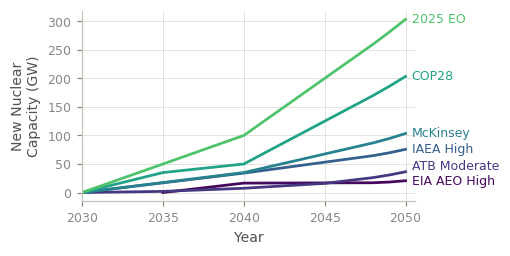

In [10]:
# ---- f01b: the new-nuclear schedules alone (paper Fig 2a since 2026-09-09) --------------
# Ethan (09-09): one panel, the additions-basis mandate of each schedule ("new nuclear"),
# no program wording. The SMR-program mandate IS the new-capacity path (floor = 0), so it
# is the schedule itself.
# Single panel: no title (house rule); the y label carries the meaning.
# 2026-09-23 (`_edit_20260923_fig2a.py`, draft-v3 comments C7/C8/C9): shorter panel, bigger
# type, Title Case axis labels, Capitalized target names, and the panel starts in 2030.
# The target AMOUNT is not printed here: a target is a TOTAL 2050 capacity, this panel plots
# the NEW capacity it requires. The amounts are in the Fig 2b titles and in the caption.


def get_traj(s):
    """The additions-basis mandate of schedule `s`, in MW, as ReEDS receives it."""
    cs = [c for c in SMR_CASES if parse_case(c)[1] == s and parse_case(c)[3] != "eq"]
    return TRAJ[cs[0]]

from matplotlib.ticker import MultipleLocator
# 09-23 (Ethan C7): the target names are capitalized. plotstyle.SCHED_SHORT carries them.
assert ps.SCHED_SHORT["aj"] == "ATB Moderate", "plotstyle.SCHED_SHORT is not the 09-23 capitalized set"
# 09-24 (Ethan E11): one type specification for every main figure, scaled to Fig 2's
# composed canvas so the sizes PRINT at plotstyle.PAPER_FONT.
_PF = ps.fonts(ps.PAPER_CANVAS_IN["fig2"])

fig, ax = plt.subplots(figsize=(4.0, 2.4))     # 09-24 (Ethan E10/F4): the 09-18 panel size restored
ends = {}
for s in SCHEDULES:
    tr = get_traj(s) / 1e3
    tr = tr[tr.index >= 2030]      # 09-23 (Ethan C7): the panel starts in 2030, no backcast
    nz = tr[tr > 0]
    if len(nz):                    # blank the pre-start zero run,
        tr = tr[tr.index >= int(nz.index.min()) - 1]  # keep one zero year
    ax.plot(tr.index, tr.values, color=SCHED_C[s], lw=1.8)
    ends[s] = (tr.index[-1], float(tr.values[-1]))
ax.set_xlabel("Year", fontsize=_PF["axis_label"])                # 09-23: Title Case (Ethan)
# two lines: the panel is short, and one line of this label is longer than the axes are tall
ax.set_ylabel("New Nuclear\nCapacity (GW)", fontsize=_PF["axis_label"])   # 09-23: Title Case (Ethan C7, Cole C8)
ax.set_xlim(2030, 2050.6)
ax.xaxis.set_major_locator(MultipleLocator(5))                   # whole years, five apart
ax.tick_params(labelsize=_PF["tick"])                            # 09-24: plotstyle.PAPER_FONT (E11)
fig.tight_layout()
# end labels, pushed apart by one line of their own type where the 2050 values sit closer than
# that; the label x stays at the line end and the label hangs outside the axes (tight bbox catches it)
ax.set_ylim(*ax.get_ylim())
_gap = (ax.get_ylim()[1] - ax.get_ylim()[0]) * ((_PF["annotation"] + 1.5) / 72) / (fig.get_figheight() * ax.get_position().height)
_ylab, _prev = {}, None
for s in sorted(ends, key=lambda k: ends[k][1]):
    y = ends[s][1] if _prev is None else max(ends[s][1], _prev + _gap)
    _ylab[s], _prev = y, y
for s in SCHEDULES:
    ax.annotate(ps.SCHED_SHORT[s], (ends[s][0], _ylab[s]), xytext=(4, 0), textcoords="offset points",
                color=SCHED_C[s], fontsize=_PF["annotation"], va="center", annotation_clip=False)
savefig(fig, "f01b_new_nuclear_trajectories.png")
plt.show()

In [11]:
# ---- objective sanity: p05 <= p50 <= p95 inside each schedule ----------------------
rows = []
for s in SCHEDULES:
    o = {p: OBJ[f"smr100_{s}_{p}"] for p in ("p05", "p50", "p95")}
    rows.append(dict(schedule=s, **{k: f"{v:.4e}" for k, v in o.items()},
                     ordered=bool(o["p05"] <= o["p50"] <= o["p95"])))
for s in SCHEDULES:
    o = {p: OBJ[f"large100_{s}_{p}"] for p in ("p05", "p50", "p95")}
    rows.append(dict(schedule=f"{s} (large)", **{k: f"{v:.4e}" for k, v in o.items()},
                     ordered=bool(o["p05"] <= o["p50"] <= o["p95"])))
obj_tbl = pd.DataFrame(rows)
assert obj_tbl["ordered"].all(), obj_tbl
print(obj_tbl.to_string(index=False))
print("objective is ordered p05 <= p50 <= p95 in all six schedules, both families.")

     schedule        p05        p50        p95  ordered
          eia 1.6171e+12 1.6319e+12 1.6494e+12     True
           aj 1.6139e+12 1.6562e+12 1.7004e+12     True
         iaea 1.5836e+12 1.6343e+12 1.6947e+12     True
          mck 1.5672e+12 1.6346e+12 1.7283e+12     True
        cop28 1.5060e+12 1.6468e+12 1.8132e+12     True
           eo 1.4470e+12 1.6255e+12 1.8856e+12     True
  eia (large) 1.6245e+12 1.6350e+12 1.6464e+12     True
   aj (large) 1.6362e+12 1.6636e+12 1.6988e+12     True
 iaea (large) 1.6083e+12 1.6476e+12 1.6920e+12     True
  mck (large) 1.6049e+12 1.6661e+12 1.7365e+12     True
cop28 (large) 1.5873e+12 1.7168e+12 1.8304e+12     True
   eo (large) 1.5690e+12 1.7212e+12 1.9051e+12     True
objective is ordered p05 <= p50 <= p95 in all six schedules, both families.


## 4. Where the mandates bind, and where they do not

`t02` lists every clearly slack mandated year, with the overbuild ratio (built capacity over the
floor). A slack year means the model builds past the floor on its own; the shadow price is then
zero, and the required credit of that year is zero. Adverse findings get equal prominence:
`smr100_eia_p05` overbuilds one of its five mandated years, and every large-reactor run has two
clearly slack years (2026 and 2029), where the existing fleet meets the early floor.

In [12]:
# ---- t02: slack years ---------------------------------------------------------------
slack = DUALS[DUALS["clearly_slack"]].copy()
slack["overbuild_ratio"] = (slack["cap_MW"] / slack["mandate_MW"]).round(3)
t02 = slack[["case", "t", "mandate_MW", "cap_MW", "slack_MW", "overbuild_ratio"]]
t02 = t02.sort_values(["case", "t"])
t02.to_csv(EXPORTS / "t02_slack_years.csv", index=False)
print(t02.to_string(index=False))
print(f"\n{len(t02)} clearly slack (case, year) points across the {len(CASES)} runs.")

              case    t  mandate_MW  cap_MW  slack_MW  overbuild_ratio
   large100_aj_p05 2026     97000.0 97636.7     636.7            1.007
   large100_aj_p05 2029     97000.0 97918.9     918.9            1.009
   large100_aj_p50 2026     97000.0 97636.7     636.7            1.007
   large100_aj_p50 2029     97000.0 97918.9     918.9            1.009
   large100_aj_p95 2026     97000.0 97636.7     636.7            1.007
   large100_aj_p95 2029     97000.0 97918.9     918.9            1.009
large100_cop28_p05 2026     97000.0 97636.7     636.7            1.007
large100_cop28_p05 2029     97000.0 97918.9     918.9            1.009
large100_cop28_p50 2026     97000.0 97636.7     636.7            1.007
large100_cop28_p50 2029     97000.0 97918.9     918.9            1.009
large100_cop28_p95 2026     97000.0 97636.7     636.7            1.007
large100_cop28_p95 2029     97000.0 97918.9     918.9            1.009
  large100_eia_p05 2026     97000.0 97636.7     636.7            1.007
  larg

## 5. Shadow-price summary, the large-over-SMR ratio and the bridge shape

`t03` summarizes each run's binding shadow prices (mean, peak, peak year, 2050 value) in 2024
$/kW-yr and asserts that the shadow price is monotone in the cost sample (P95 ≥ P50 ≥ P5 in
every year, both programs).

`t15` (Supplementary Table 15) compares the two programs like for like: for each schedule and
cost sample it averages the shadow price over the years in which both the large-reactor and the
SMR run bind, and divides. The ratio is cost-sample dependent: the large-reactor program needs
about 1.4 to 3.5 times the SMR support in the cheapest samples, about 1.23 to 1.36 times at the
median, and near parity in the most expensive samples. The two programs differ in mandated
technology, mandate basis and drawn cost world, so the ratio is a conditional what-if, not a
causal comparison.

`t04` measures the shape of each run's shadow-price path (the *bridge* reading: support that
decays as the fleet learns): the peak year, the 2050 value over the peak, the first year below
half of the peak, and the count of mandated years at a zero shadow price. Notebooks 08 and 13a
read `t04`.

In [13]:
# ---- t03: dual summary per case ------------------------------------------------------
KWYR = 1e-3      # $/MW-yr -> $/kW-yr
rows = []
for c in CASES:
    d = DUALS[(DUALS["case"] == c) & DUALS["mandated"]].set_index("t").sort_index()
    b = d[d["binding"]]["dual_2024_MWyr"]
    rows.append(dict(
        case=c,
        n_binding=len(b),
        mean_binding_dual_2024_kWyr=round(float(b.mean()) * KWYR, 1) if len(b) else 0.0,
        peak_dual_2024_kWyr=round(float(b.max()) * KWYR, 1) if len(b) else 0.0,
        peak_year=int(b.idxmax()) if len(b) else None,
        dual_2050_2024_kWyr=round(float(d.loc[2050, "dual_2024_MWyr"]) * KWYR, 1)
                            if 2050 in d.index else 0.0,
    ))
t03 = pd.DataFrame(rows)
t03.to_csv(EXPORTS / "t03_dual_summary.csv", index=False)
print(t03.to_string(index=False))

# pointwise monotonicity across the cost world, re-verified from the export
for s in SCHEDULES:
    piv = (DUALS[(DUALS["family"] == "smr") & (DUALS["schedule"] == s)
                 & (DUALS["variant"] != "eq")]
           .pivot_table(index="t", columns="pct", values="dual_2004_MWyr"))
    assert ((piv["p95"] >= piv["p50"] - 1e-6) & (piv["p50"] >= piv["p05"] - 1e-6)).all(), s
for s in SCHEDULES:
    piv = (DUALS[(DUALS["family"] == "large") & (DUALS["schedule"] == s)]
           .pivot_table(index="t", columns="pct", values="dual_2004_MWyr"))
    assert ((piv["p95"] >= piv["p50"] - 1e-6) & (piv["p50"] >= piv["p05"] - 1e-6)).all(), s
print("dual is monotone p95 >= p50 >= p05 pointwise in all six schedules, "
      "both families.")

              case  n_binding  mean_binding_dual_2024_kWyr  peak_dual_2024_kWyr  peak_year  dual_2050_2024_kWyr
    smr100_eia_p05          4                         70.1                176.5       2038                  4.4
    smr100_eia_p50          5                        334.4                405.9       2038                310.2
    smr100_eia_p95          5                        610.1                693.0       2038                581.3
     smr100_aj_p05         10                        200.6                370.7       2031                 69.0
     smr100_aj_p50         10                        389.7                441.1       2033                368.1
     smr100_aj_p95         10                        698.1                758.6       2033                627.7
   smr100_iaea_p05         10                        117.8                305.5       2031                 58.9
   smr100_iaea_p50         10                        370.8                746.4       2031              

In [14]:
# ---- t15: large100 against smr100 over shared binding years (Supplementary Table 15) ----
rows15 = []
for s in SCHEDULES:
    for p in ("p05", "p50", "p95"):
        dl = (DUALS[(DUALS["case"] == f"large100_{s}_{p}") & DUALS["binding"]]
              .set_index("t")["dual_2024_MWyr"])
        ds = (DUALS[(DUALS["case"] == f"smr100_{s}_{p}") & DUALS["binding"]]
              .set_index("t")["dual_2024_MWyr"])
        shared = sorted(set(dl.index) & set(ds.index))
        rows15.append(dict(
            schedule=s, pct=p, n_shared_binding=len(shared),
            large_mean_2024_kWyr=(round(float(dl.reindex(shared).mean()) * KWYR, 1)
                                  if shared else None),
            smr_mean_2024_kWyr=(round(float(ds.reindex(shared).mean()) * KWYR, 1)
                                if shared else None),
            ratio_large_over_smr=(round(float(dl.reindex(shared).mean()
                                              / ds.reindex(shared).mean()), 2)
                                  if shared else None)))
t15 = pd.DataFrame(rows15)
t15.to_csv(EXPORTS / "t15_large_ratio.csv", index=False)
piv15 = (t15.pivot_table(index="schedule", columns="pct", values="ratio_large_over_smr")
         .reindex(SCHEDULES))
print("large100 / smr100 mean binding dual ratio (shared binding years):")
print(piv15.to_string())

large100 / smr100 mean binding dual ratio (shared binding years):
pct        p05   p50   p95
schedule                  
eia       3.53  1.25  1.02
aj        1.44  1.29  0.95
iaea      2.22  1.24  0.99
mck       2.17  1.27  0.98
cop28     2.23  1.23  0.97
eo        2.36  1.36  1.00


In [15]:
# ---- t04: bridge metrics --------------------------------------------------------------
rows = []
for c in CASES:
    d = DUALS[(DUALS["case"] == c) & DUALS["mandated"]].set_index("t").sort_index()
    b = d[d["binding"]]["dual_2004_MWyr"]
    if not len(b):
        rows.append(dict(case=c, peak_year=None, end_over_peak=None,
                         first_year_below_half_peak=None,
                         n_zero_dual_mandated_years=int((~d["binding"]).sum())))
        continue
    peak_t, peak = int(b.idxmax()), float(b.max())
    end = float(d.loc[2050, "dual_2004_MWyr"]) if 2050 in d.index else 0.0
    below = [t for t in b.index if t > peak_t and b[t] < 0.5 * peak]
    zero_after = [t for t in d.index if t > peak_t and not d.loc[t, "binding"]]
    first_half = min(below + zero_after) if (below or zero_after) else None
    rows.append(dict(case=c, peak_year=peak_t, end_over_peak=round(end / peak, 2),
                     first_year_below_half_peak=first_half,
                     n_zero_dual_mandated_years=int((~d["binding"]).sum())))
t04 = pd.DataFrame(rows)
t04.to_csv(EXPORTS / "t04_bridge_metrics.csv", index=False)
print(t04.to_string(index=False))

              case  peak_year  end_over_peak  first_year_below_half_peak  n_zero_dual_mandated_years
    smr100_eia_p05       2038           0.03                      2041.0                           1
    smr100_eia_p50       2038           0.76                         NaN                           0
    smr100_eia_p95       2038           0.84                         NaN                           0
     smr100_aj_p05       2031           0.19                      2041.0                           0
     smr100_aj_p50       2033           0.83                         NaN                           0
     smr100_aj_p95       2033           0.83                         NaN                           0
   smr100_iaea_p05       2031           0.19                      2034.0                           0
   smr100_iaea_p50       2031           0.31                      2035.0                           0
   smr100_iaea_p95       2031           0.82                         NaN                   

## 6. System costs and system NPV (Supplementary Figs. 8 and 9)

No run is without a mandate, so the system cost *of* the mandate against a no-mandate
counterfactual is not computable here. Three objects are computable. `t05` groups the 25 ReEDS
`systemcost` streams into seven buckets per run and year (2024 $B/yr; policy-credit streams
are negative and keep their sign). `t06` gives two clean comparisons per schedule and year: the
P95 − P5 spread inside one schedule (the mandate is identical, so the spread isolates the drawn
cost world) and the SMR − large-reactor difference at P50 (a conditional what-if). `t07` is the
system net present value (NPV) over 2026–2050:

NPV = Σ over calendar years y in [2026, 2050] of C(m(y)) / DR^(y − 2026),

where C(t) is the total annual system cost of solve year t and m(y) maps a calendar year to the
solve year that represents it (solve year t covers the years from t to the next solve year minus
one). Investment enters as a lump in the build year and the window stops at 2050, so late builds
carry full capital cost and none of their post-2050 value; this end effect penalizes the ambitious
schedules.

Supplementary Fig. 8 stacks `f08` (the cost anatomy of the reference run `smr100_eia_p50`) over
`f09` (total annual system cost fans per schedule). Supplementary Fig. 9 stacks `f10` (panels a
and b: the P95 − P5 spread and the SMR − large difference) over `f11` (panel c: the NPV against
2050 ambition). Cross-schedule levels mix the mandate with the drawn cost world; they are
descriptive.

In [16]:
# ---- bucket the 25 streams --------------------------------------------------------------
BUCKETS = {
    "generation capex": ["inv_investment_capacity_costs",
                         "inv_investment_refurbishment_capacity",
                         "inv_investment_spurline_costs_rsc_technologies"],
    "transmission capex": ["inv_transmission_interzone_ac_investment",
                           "inv_transmission_interzone_dc_investment",
                           "inv_transmission_intrazone_investment"],
    "converter + H2 capex": ["inv_converter_costs", "inv_h2_production", "inv_h2_storage"],
    "fuel": ["op_fuelcosts_objfn"],
    "FOM": ["op_fom_costs", "op_consume_fom", "op_spurline_fom",
            "op_transmission_fom", "op_transmission_intrazone_fom"],
    "VOM + other op": ["op_vom_costs", "op_startcost", "op_acp_compliance_costs",
                       "op_co2_transport_storage", "op_h2_storage",
                       "op_h2_transport_intrareg"],
    "policy credits (neg.)": ["inv_itc_payments_negative", "op_co2_incentive_negative",
                              "op_h2_ptc_payments_negative", "op_ptc_payments_negative"],
}
covered = sorted(x for v in BUCKETS.values() for x in v)
assert covered == STREAMS, set(STREAMS) ^ set(covered)
S2B = {x: b for b, v in BUCKETS.items() for x in v}

SYSCOST["bucket"] = SYSCOST["sys_costs"].map(S2B)
SYSCOST["B2024"] = SYSCOST["Value"] * TO2024 / 1e9
CB = (SYSCOST.groupby(["case", "bucket", "t"], as_index=False)["B2024"].sum())
CTOT = SYSCOST.groupby(["case", "t"])["B2024"].sum().unstack("t")     # 2024$B per year
CB.to_csv(EXPORTS / "t05_systemcost_by_case.csv", index=False)

# consistency: raw_inv/raw_op against the stream sums (context, not a gate)
inv_streams = [x for x in STREAMS if x.startswith("inv_") and not x.endswith("negative")]
c = REF
si = SYSCOST[(SYSCOST["case"] == c) & SYSCOST["sys_costs"].isin(inv_streams)]
si = si.groupby("t")["Value"].sum()
ri = RAWIO[c][0].reindex(si.index)
print(f"{c}: raw_inv_cost vs positive inv streams, max rel diff "
      f"{float(((si - ri).abs() / ri.clip(lower=1)).max()):.2e}")
itc_mag = {k: abs(v) * TO2024 / 1e9 for k, v in ITC_TOT.items()}
print(f"ITC tax expenditure magnitude (2024$B, recorded negative in the h5): "
      f"{min(itc_mag.values()):.1f} .. {max(itc_mag.values()):.1f} "
      "- other techs keep their ITC; nuclear has none (QA B10-B13).")

smr100_eia_p50: raw_inv_cost vs positive inv streams, max rel diff 1.70e-01
ITC tax expenditure magnitude (2024$B, recorded negative in the h5): 205.0 .. 207.2 - other techs keep their ITC; nuclear has none (QA B10-B13).


saved -> analysis\results\exports\07\f08_cost_decomposition_ref.png


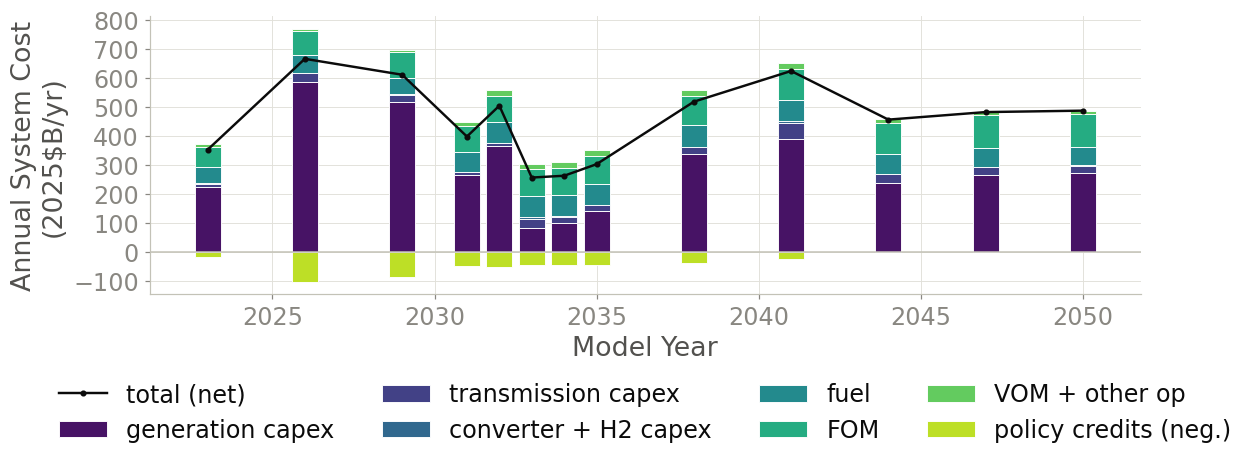

In [17]:
# ---- f08: cost anatomy of the reference case ----------------------------------------------
ref = CB[(CB["case"] == REF) & (CB["t"] >= 2023)].pivot_table(
    index="t", columns="bucket", values="B2024")
order = [b for b in BUCKETS if b in ref.columns]
bcol = {b: c for b, c in zip(BUCKETS, mpl.cm.viridis(np.linspace(0.05, 0.9, len(BUCKETS))))}
# 09-24 (Ethan E11, `_edit_20260924_si_type_step3_analysis.py`): Supplementary Fig. 8
# panel a. It is composed into SF13_cost_anatomy.png, which the Supplementary places
# 12.70 in wide at 6.5 in, so the type is authored at ps.fonts(12.70) and PRINTS at
# plotstyle.PAPER_FONT - 8 pt ticks, 9 pt axis labels, 8 pt legend.
_PF = ps.fonts(12.70)
# wider than the 09-23 (9, 4.8): the eight-entry key moves under the axes at the new
# size, and a narrower panel would leave the bars in the middle third of the page
fig, ax = plt.subplots(figsize=(11.5, 4.5))
bottom_pos = np.zeros(len(ref))
bottom_neg = np.zeros(len(ref))
for b in order:
    v = ref[b].fillna(0).to_numpy() * F2025          # 2024$ -> 2025$ at display
    base = np.where(v >= 0, bottom_pos, bottom_neg)
    ax.bar(ref.index, v, bottom=base, width=0.8, label=b, color=bcol[b],
           edgecolor=SURFACE, linewidth=0.6)
    bottom_pos += np.clip(v, 0, None)
    bottom_neg += np.clip(v, None, 0)
tot = ref.sum(axis=1)
ax.plot(ref.index, tot * F2025, color=INK, lw=1.6, marker="o", ms=3,
        label="total (net)")
ax.axhline(0, color=EDGE_C, lw=1)
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=11))  # ticks below 0 too
ax.set_xlabel("Model Year", fontsize=_PF["axis_label"])
# two lines: one line of this label is longer than the panel is tall at the new size
ax.set_ylabel(f"Annual System Cost\n{USD25B_YR}",
              fontsize=_PF["axis_label"])
# the legend has eight entries; at the printed size four columns under the axes read
# better than two columns over the bars
ax.legend(fontsize=_PF["legend"], ncols=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.24), frameon=False)
ax.tick_params(labelsize=_PF["tick"])
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=7, integer=True))
fig.tight_layout()
savefig(fig, "f08_cost_decomposition_ref.png")
plt.show()

saved -> analysis\results\exports\07\f09_cost_totals.png


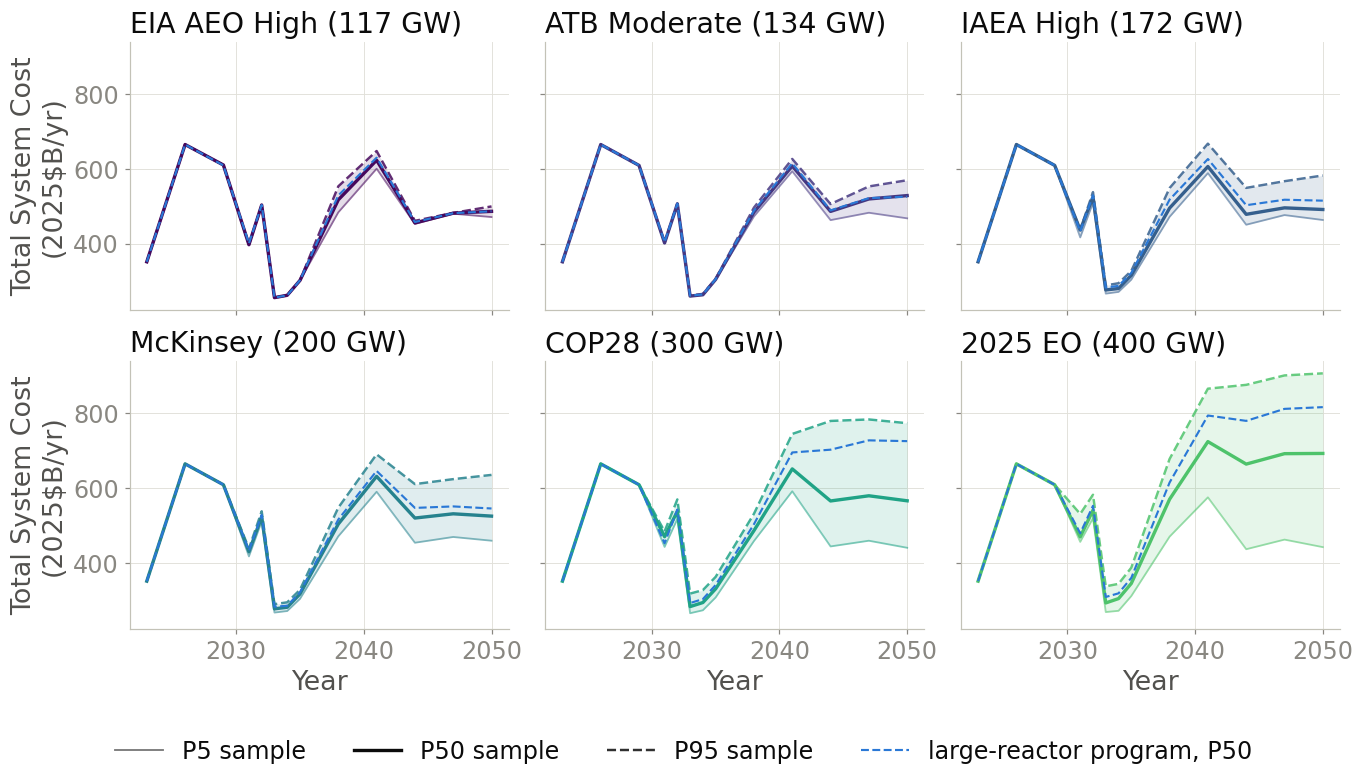

In [18]:
# ---- f09: total annual system cost fans -----------------------------------------------------
# 09-24 (Ethan E11): Supplementary Fig. 8 panel b, composed into SF13_cost_anatomy.png
# at 12.70 in and printed at 6.5 in, so the type authors at ps.fonts(12.70).
_PF = ps.fonts(12.70)
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.5), sharex=True, sharey=True)
for k, s in enumerate(SCHEDULES):
    ax = axes.flat[k]
    piv = {p: CTOT.loc[f"smr100_{s}_{p}"] * F2025 for p in ("p05", "p50", "p95")}
    yrs = [t for t in YEARS_RUN if t >= 2023]
    ax.fill_between(yrs, piv["p05"][yrs], piv["p95"][yrs], color=SCHED_C[s],
                    alpha=0.14, lw=0)
    for p in ("p05", "p50", "p95"):
        ax.plot(yrs, piv[p][yrs], color=SCHED_C[s], **PCT_STYLE[p])
    lg = CTOT.loc[f"large100_{s}_p50"] * F2025
    ax.plot(yrs, lg[yrs], color=COL["large"], lw=1.4, ls="--")
    # 09-24: ps.SCHED_LABEL is the plot authority for the target-trajectory names;
    # the local SCHED_LABEL still reads "Abou-Jaoude", a name Ethan retired on 09-18.
    ax.set_title(ps.SCHED_LABEL[s], fontsize=_PF["panel_title"])
    ax.tick_params(labelsize=_PF["tick"])
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(10))
    if k % 3 == 0:
        ax.set_ylabel(f"Total System Cost\n{USD25B_YR}",
                      fontsize=_PF["axis_label"])
    if k >= 3:
        ax.set_xlabel("Year", fontsize=_PF["axis_label"])
# 09-24: the key is a figure legend under the grid. At the printed size it no longer
# fits inside the first panel without covering that panel's tick labels.
_key = ([mpl.lines.Line2D([], [], color=INK, **PCT_STYLE[p])
         for p in ("p05", "p50", "p95")]
        + [mpl.lines.Line2D([], [], color=COL["large"], lw=1.4, ls="--")])
fig.tight_layout()
fig.legend(_key, [PCT_LABEL["p05"], PCT_LABEL["p50"], PCT_LABEL["p95"],
                  f"{PROGRAM_LABEL['large100']}, P50"], fontsize=_PF["legend"],
           ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.01), frameon=False)
savefig(fig, "f09_cost_totals.png")
plt.show()

saved -> analysis\results\exports\07\f10_within_schedule_spread.png


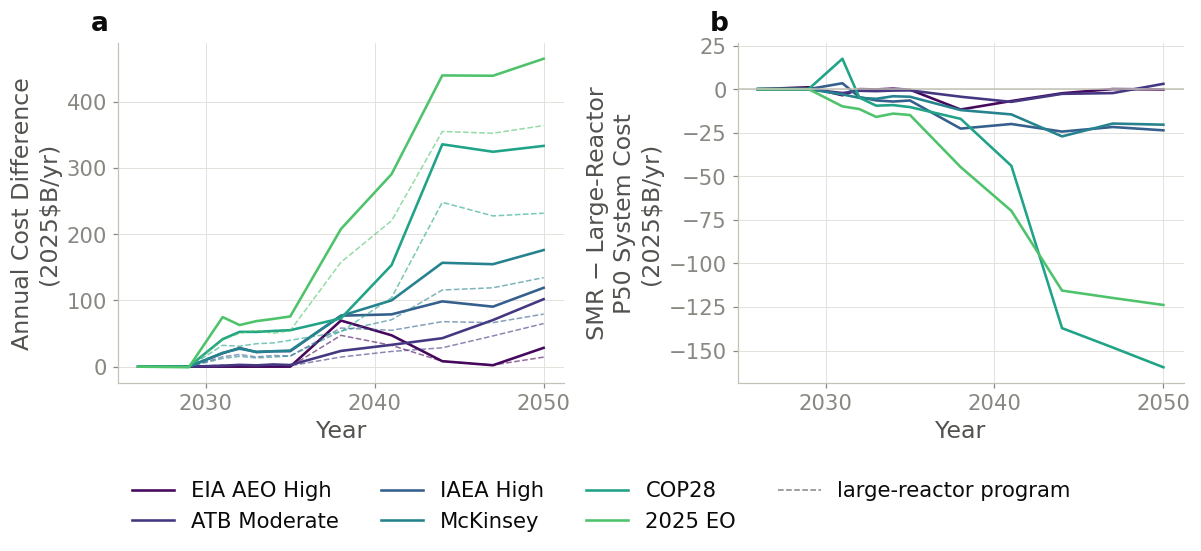

schedule    t  p95_minus_p05_B2024  large_p95_minus_p05_B2024  smr_minus_large_p50_B2024
     eia 2050                27.71                      14.04                      -0.16
      aj 2050                99.34                      63.43                       2.97
    iaea 2050               116.05                      77.37                     -23.04
     mck 2050               171.57                     131.01                     -19.88
   cop28 2050               324.80                     225.82                    -155.55
      eo 2050               453.01                     354.69                    -120.71


In [19]:
# ---- f10 + t06: the two clean cost comparisons ----------------------------------------------
yrs = [t for t in YEARS_RUN if t >= 2026]
# 09-24 (Ethan E11): Supplementary Fig. 9 panels a and b. Composed into
# SF14_spread_and_npv.png, which agent SIF stacks one panel per row, 11.24 in wide,
# printed at 6.5 in - so the type authors at ps.fonts(11.24).
_PF = ps.fonts(11.24)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
rows = []
for s in SCHEDULES:
    spread = CTOT.loc[f"smr100_{s}_p95"] - CTOT.loc[f"smr100_{s}_p05"]
    spread_l = CTOT.loc[f"large100_{s}_p95"] - CTOT.loc[f"large100_{s}_p05"]
    delta = CTOT.loc[f"smr100_{s}_p50"] - CTOT.loc[f"large100_{s}_p50"]
    axes[0].plot(yrs, spread[yrs] * F2025, color=SCHED_C[s], lw=1.7,
                 label=ps.SCHED_SHORT[s])   # short names: the full labels widened
                                            # the composite and cost SF9 a point of type
    axes[0].plot(yrs, spread_l[yrs] * F2025, color=SCHED_C[s], lw=1.0, ls="--",
                 alpha=0.6)
    axes[1].plot(yrs, delta[yrs] * F2025, color=SCHED_C[s], lw=1.7)
    for t in yrs:
        rows.append(dict(schedule=s, t=t,
                         p95_minus_p05_B2024=round(float(spread[t]), 2),
                         large_p95_minus_p05_B2024=round(float(spread_l[t]), 2),
                         smr_minus_large_p50_B2024=round(float(delta[t]), 2)))
# the long y labels wrap: at the printed size one line is longer than the panel is tall
axes[0].set_ylabel(f"Annual Cost Difference\n{USD25B_YR}",
                   fontsize=_PF["axis_label"])
h10, l10 = axes[0].get_legend_handles_labels()
# 09-24c: a figure legend, not an axes legend: the seven named entries are
# much wider than the single panel they used to hang from, and tight_layout grew the
# canvas sideways to fit the overhang. Centred on the figure, as in f09 and f13.
_h10 = h10 + [mpl.lines.Line2D([], [], color=MUTED, lw=1.0, ls="--", alpha=0.7)]
_l10 = l10 + [PROGRAM_LABEL["large100"]]
axes[1].axhline(0, color=EDGE_C, lw=1)
# three short lines: at this type size two long ones are taller than the panel,
# and the composed figure clipped the label at both ends
axes[1].set_ylabel("SMR \u2212 Large-Reactor\nP50 System Cost\n" + USD25B_YR,
                   fontsize=_PF["axis_label"])
ps.letter_panels(axes, size=_PF["panel_letter"])
for ax in axes:
    ax.set_xlabel("Year", fontsize=_PF["axis_label"])
    ax.tick_params(labelsize=_PF["tick"])
    # three ticks, not five: the panels are narrow beside their own y labels and
    # five year labels collided at the printed size
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=3, integer=True))
fig.tight_layout()
fig.legend(_h10, _l10, fontsize=_PF["legend"], ncols=4, loc="upper center",
           bbox_to_anchor=(0.5, -0.01), frameon=False)
savefig(fig, "f10_within_schedule_spread.png")
plt.show()
t06 = pd.DataFrame(rows)
t06.to_csv(EXPORTS / "t06_cost_deltas.csv", index=False)
print(t06[t06["t"] == 2050].to_string(index=False))

system NPV, 2026-2050, mean real rate, 2024 $B:
schedule  ambition_2050_GW  smr_p05  smr_p50  smr_p95  large_p05  large_p50  large_p95  p95_minus_p05  smr_minus_large_p50
     eia             117.3   6904.6   6991.9   7087.3     6961.6     7021.9     7089.2          182.7                -30.0
      aj             134.0   6900.6   7015.3   7129.2     6974.7     7040.3     7126.8          228.6                -25.0
    iaea             172.3   6897.4   7069.4   7442.0     7050.9     7202.6     7437.9          544.6               -133.2
     mck             200.0   6899.7   7202.8   7610.9     7103.7     7312.4     7614.2          711.2               -109.6
   cop28             300.0   6887.4   7384.2   8183.1     7311.8     7816.7     8229.4         1295.7               -432.5
      eo             400.0   6900.3   7888.4   8916.2     7504.9     8375.8     9062.6         2015.9               -487.4


saved -> analysis\results\exports\07\f11_npv_vs_ambition.png


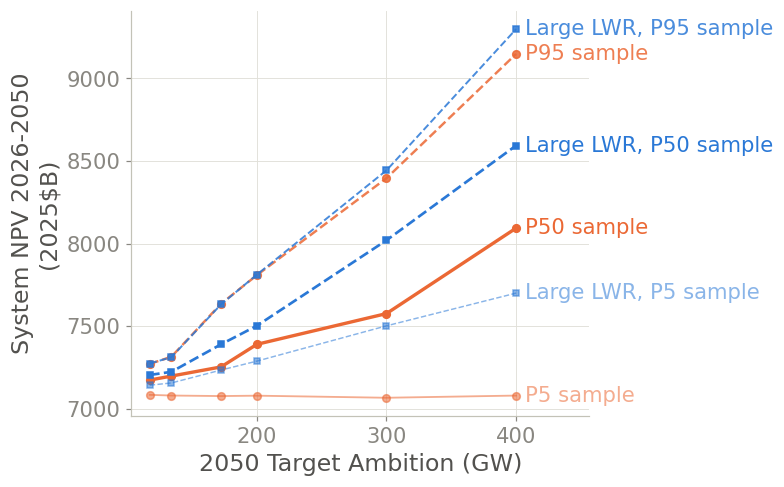

In [20]:
# ---- t07 + f11: system NPV -------------------------------------------------------------------
POST = [t for t in YEARS_RUN if t >= 2026]

def year_rep(y):
    return max(t for t in POST if t <= y)

def npv_of(series_by_t):
    return sum(float(series_by_t[year_rep(y)]) / DR ** (y - 2026)
               for y in range(2026, 2051))

NPV = {c: npv_of(CTOT.loc[c]) for c in CASES}      # 2024 $B
rows = []
for s in SCHEDULES:
    rows.append(dict(
        schedule=s, ambition_2050_GW=SCHED_GW[s],
        smr_p05=round(NPV[f"smr100_{s}_p05"], 1),
        smr_p50=round(NPV[f"smr100_{s}_p50"], 1),
        smr_p95=round(NPV[f"smr100_{s}_p95"], 1),
        large_p05=round(NPV[f"large100_{s}_p05"], 1),
        large_p50=round(NPV[f"large100_{s}_p50"], 1),
        large_p95=round(NPV[f"large100_{s}_p95"], 1),
        p95_minus_p05=round(NPV[f"smr100_{s}_p95"] - NPV[f"smr100_{s}_p05"], 1),
        smr_minus_large_p50=round(NPV[f"smr100_{s}_p50"] - NPV[f"large100_{s}_p50"], 1),
    ))
t07 = pd.DataFrame(rows)
t07.to_csv(EXPORTS / "t07_system_npv.csv", index=False)
print("system NPV, 2026-2050, mean real rate, 2024 $B:")
print(t07.to_string(index=False))

# 09-24 (Ethan E11): Supplementary Fig. 9 panel c, composed into SF14_spread_and_npv.png
# at 11.24 in and printed at 6.5 in, so the type authors at ps.fonts(11.24).
_PF = ps.fonts(11.24)
fig, ax = plt.subplots(figsize=(7, 4.5))
xs = [SCHED_GW[s] for s in SCHEDULES]
for p in ("p05", "p50", "p95"):
    ys = [NPV[f"smr100_{s}_{p}"] * F2025 for s in SCHEDULES]
    ax.plot(xs, ys, marker="o", ms=5, color=COL["smr"], **PCT_STYLE[p])
    ax.annotate(PCT_LABEL[p], (xs[-1], ys[-1]), xytext=(6, 0),
                textcoords="offset points",
                color=COL["smr"], alpha=PCT_STYLE[p]["alpha"],
                fontsize=_PF["annotation"], va="center")
for p in ("p05", "p50", "p95"):
    ys_l = [NPV[f"large100_{s}_{p}"] * F2025 for s in SCHEDULES]
    ax.plot(xs, ys_l, marker="s", ms=4, color=COL["large"], ls="--",
            lw=PCT_STYLE[p]["lw"] * 0.8, alpha=PCT_STYLE[p]["alpha"])
    ax.annotate(f"Large LWR, {PCT_LABEL[p]}", (xs[-1], ys_l[-1]), xytext=(6, 0),
                textcoords="offset points", color=COL["large"],
                fontsize=_PF["annotation"], va="center",
                alpha=PCT_STYLE[p]["alpha"])
ax.set_xlabel("2050 Target Ambition (GW)", fontsize=_PF["axis_label"])
ax.set_ylabel(f"System NPV 2026-2050\n{USD25B}",
              fontsize=_PF["axis_label"])
ax.tick_params(labelsize=_PF["tick"])
# the end labels sit outside the axes; give them room so tight bbox does not widen
# the panel past the figure it is composed with
ax.set_xlim(right=xs[-1] + 0.20 * (xs[-1] - xs[0]))
fig.tight_layout()
savefig(fig, "f11_npv_vs_ambition.png")
plt.show()

composed -> analysis\results\figures\si\SF08_cost_anatomy.png  (3816x3540 px)


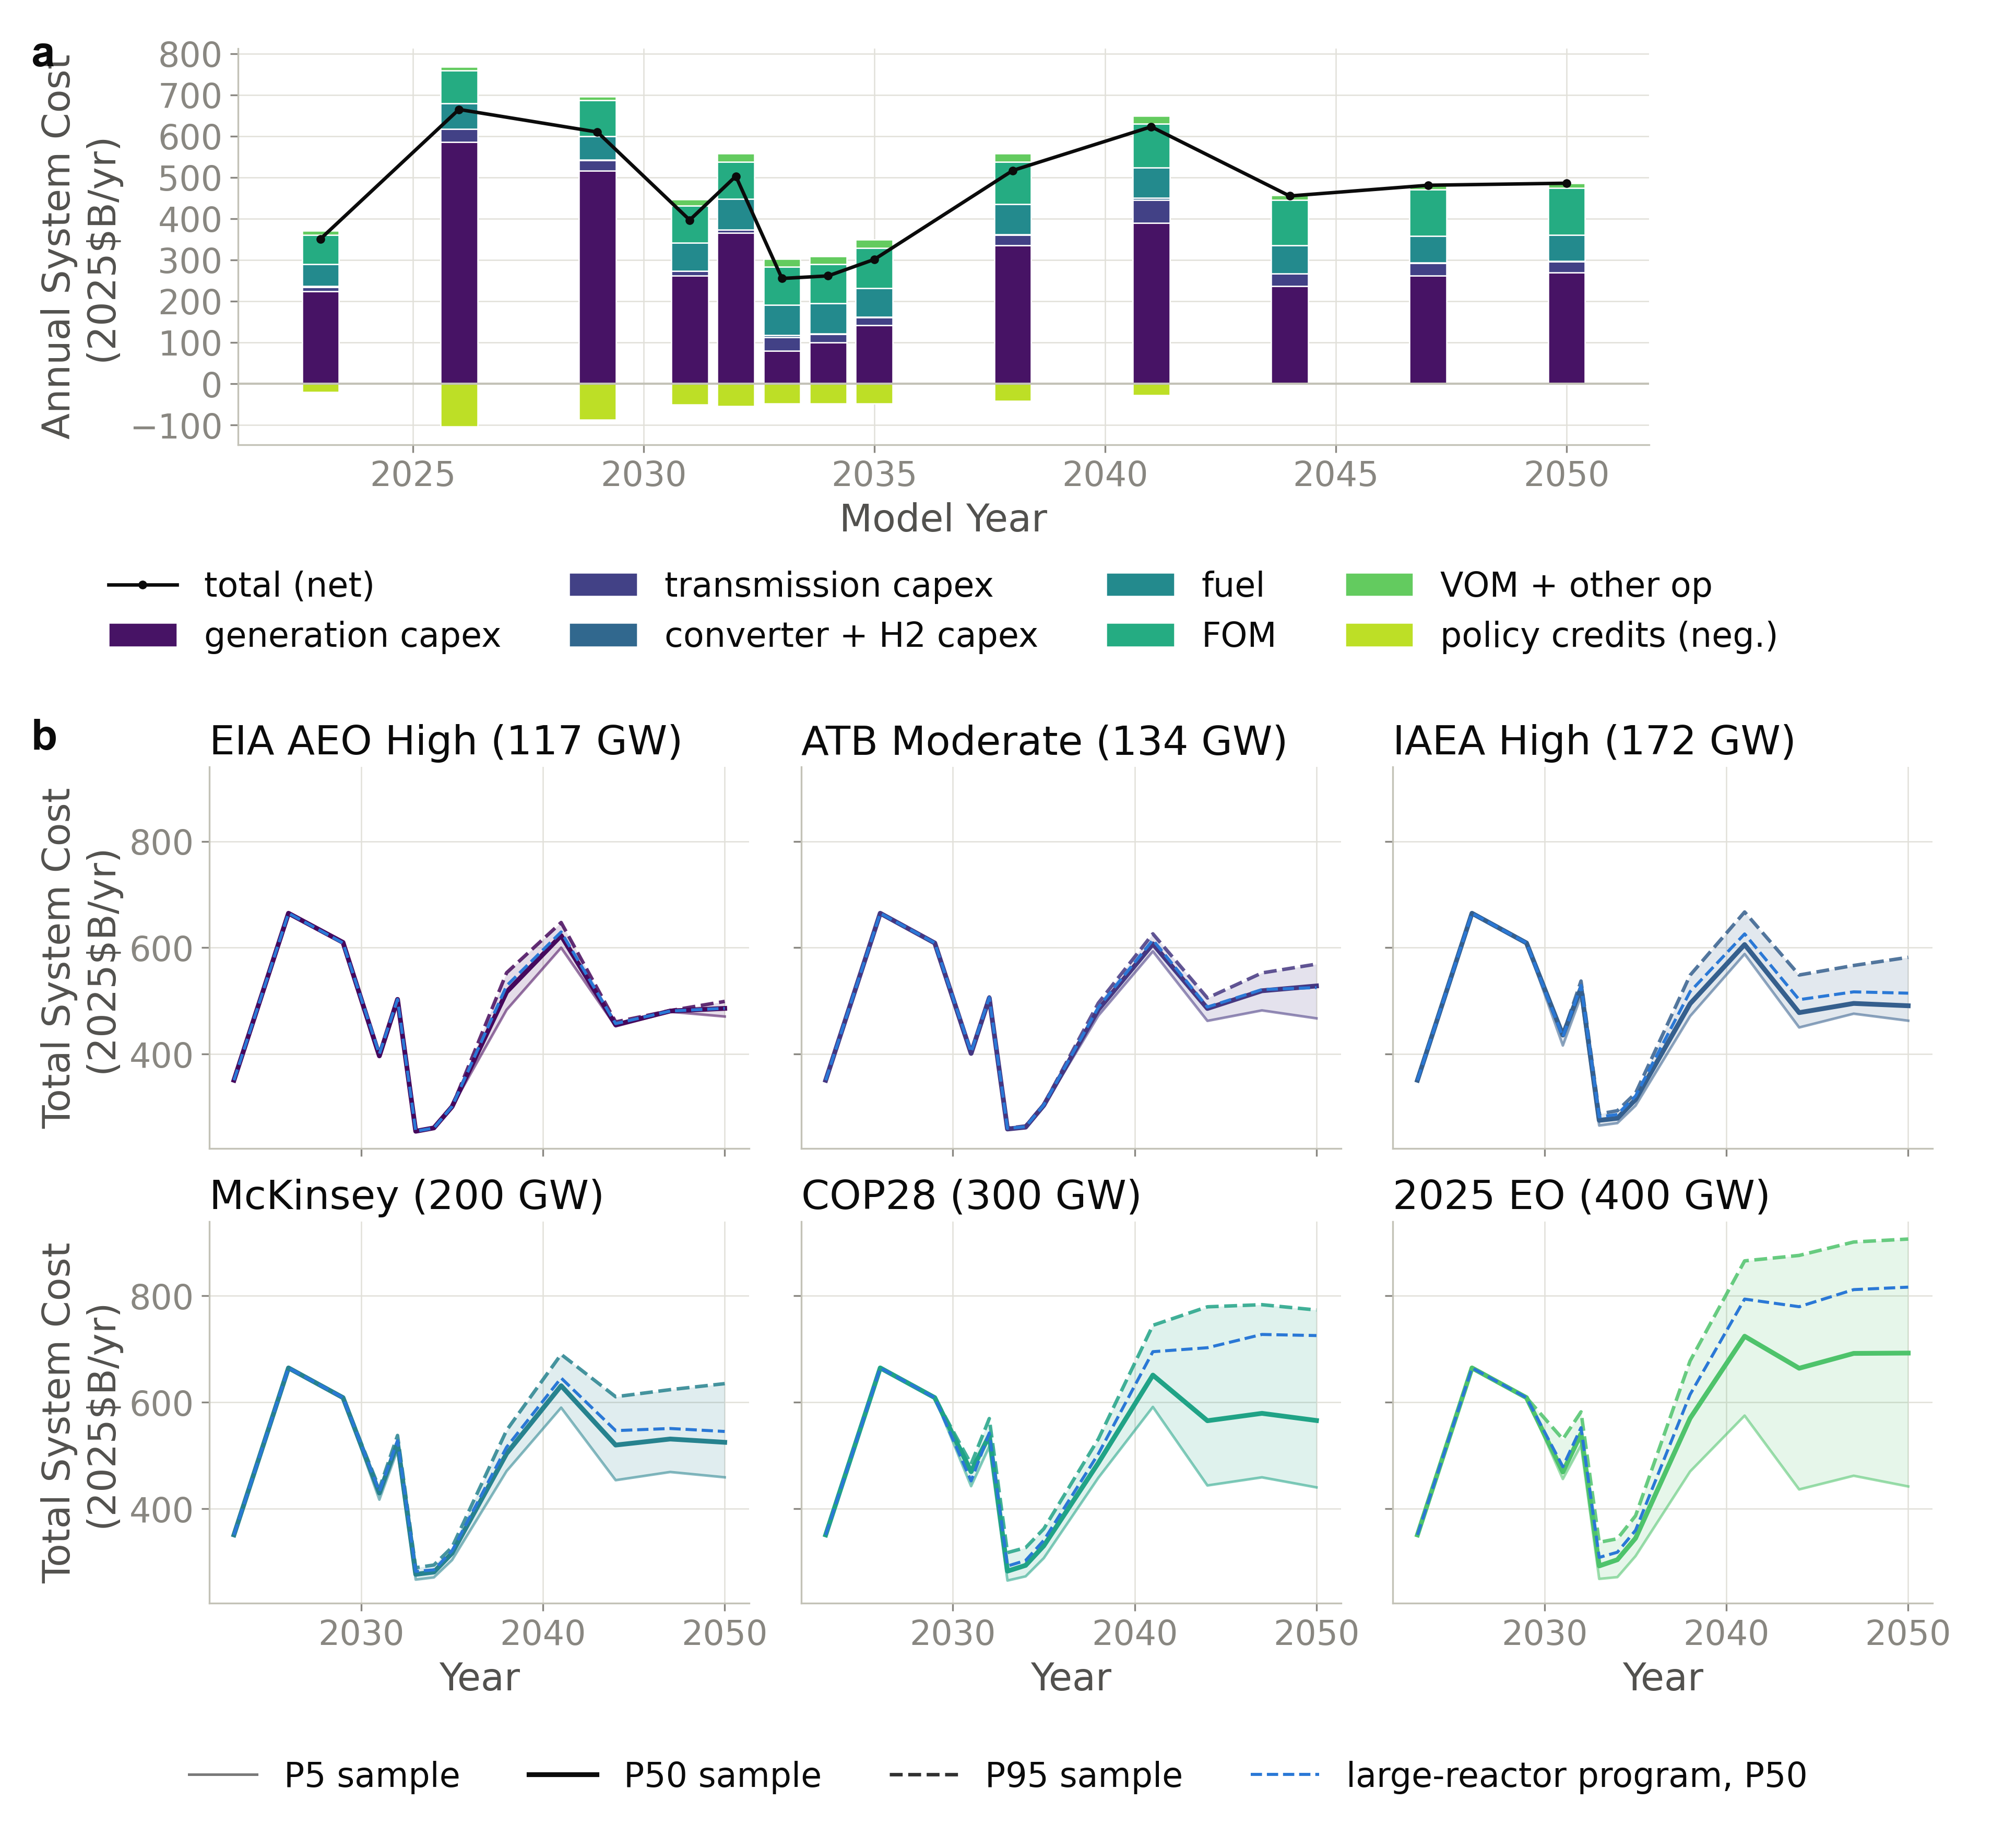

composed -> analysis\results\figures\si\SF09_spread_and_npv.png  (3370x2975 px)


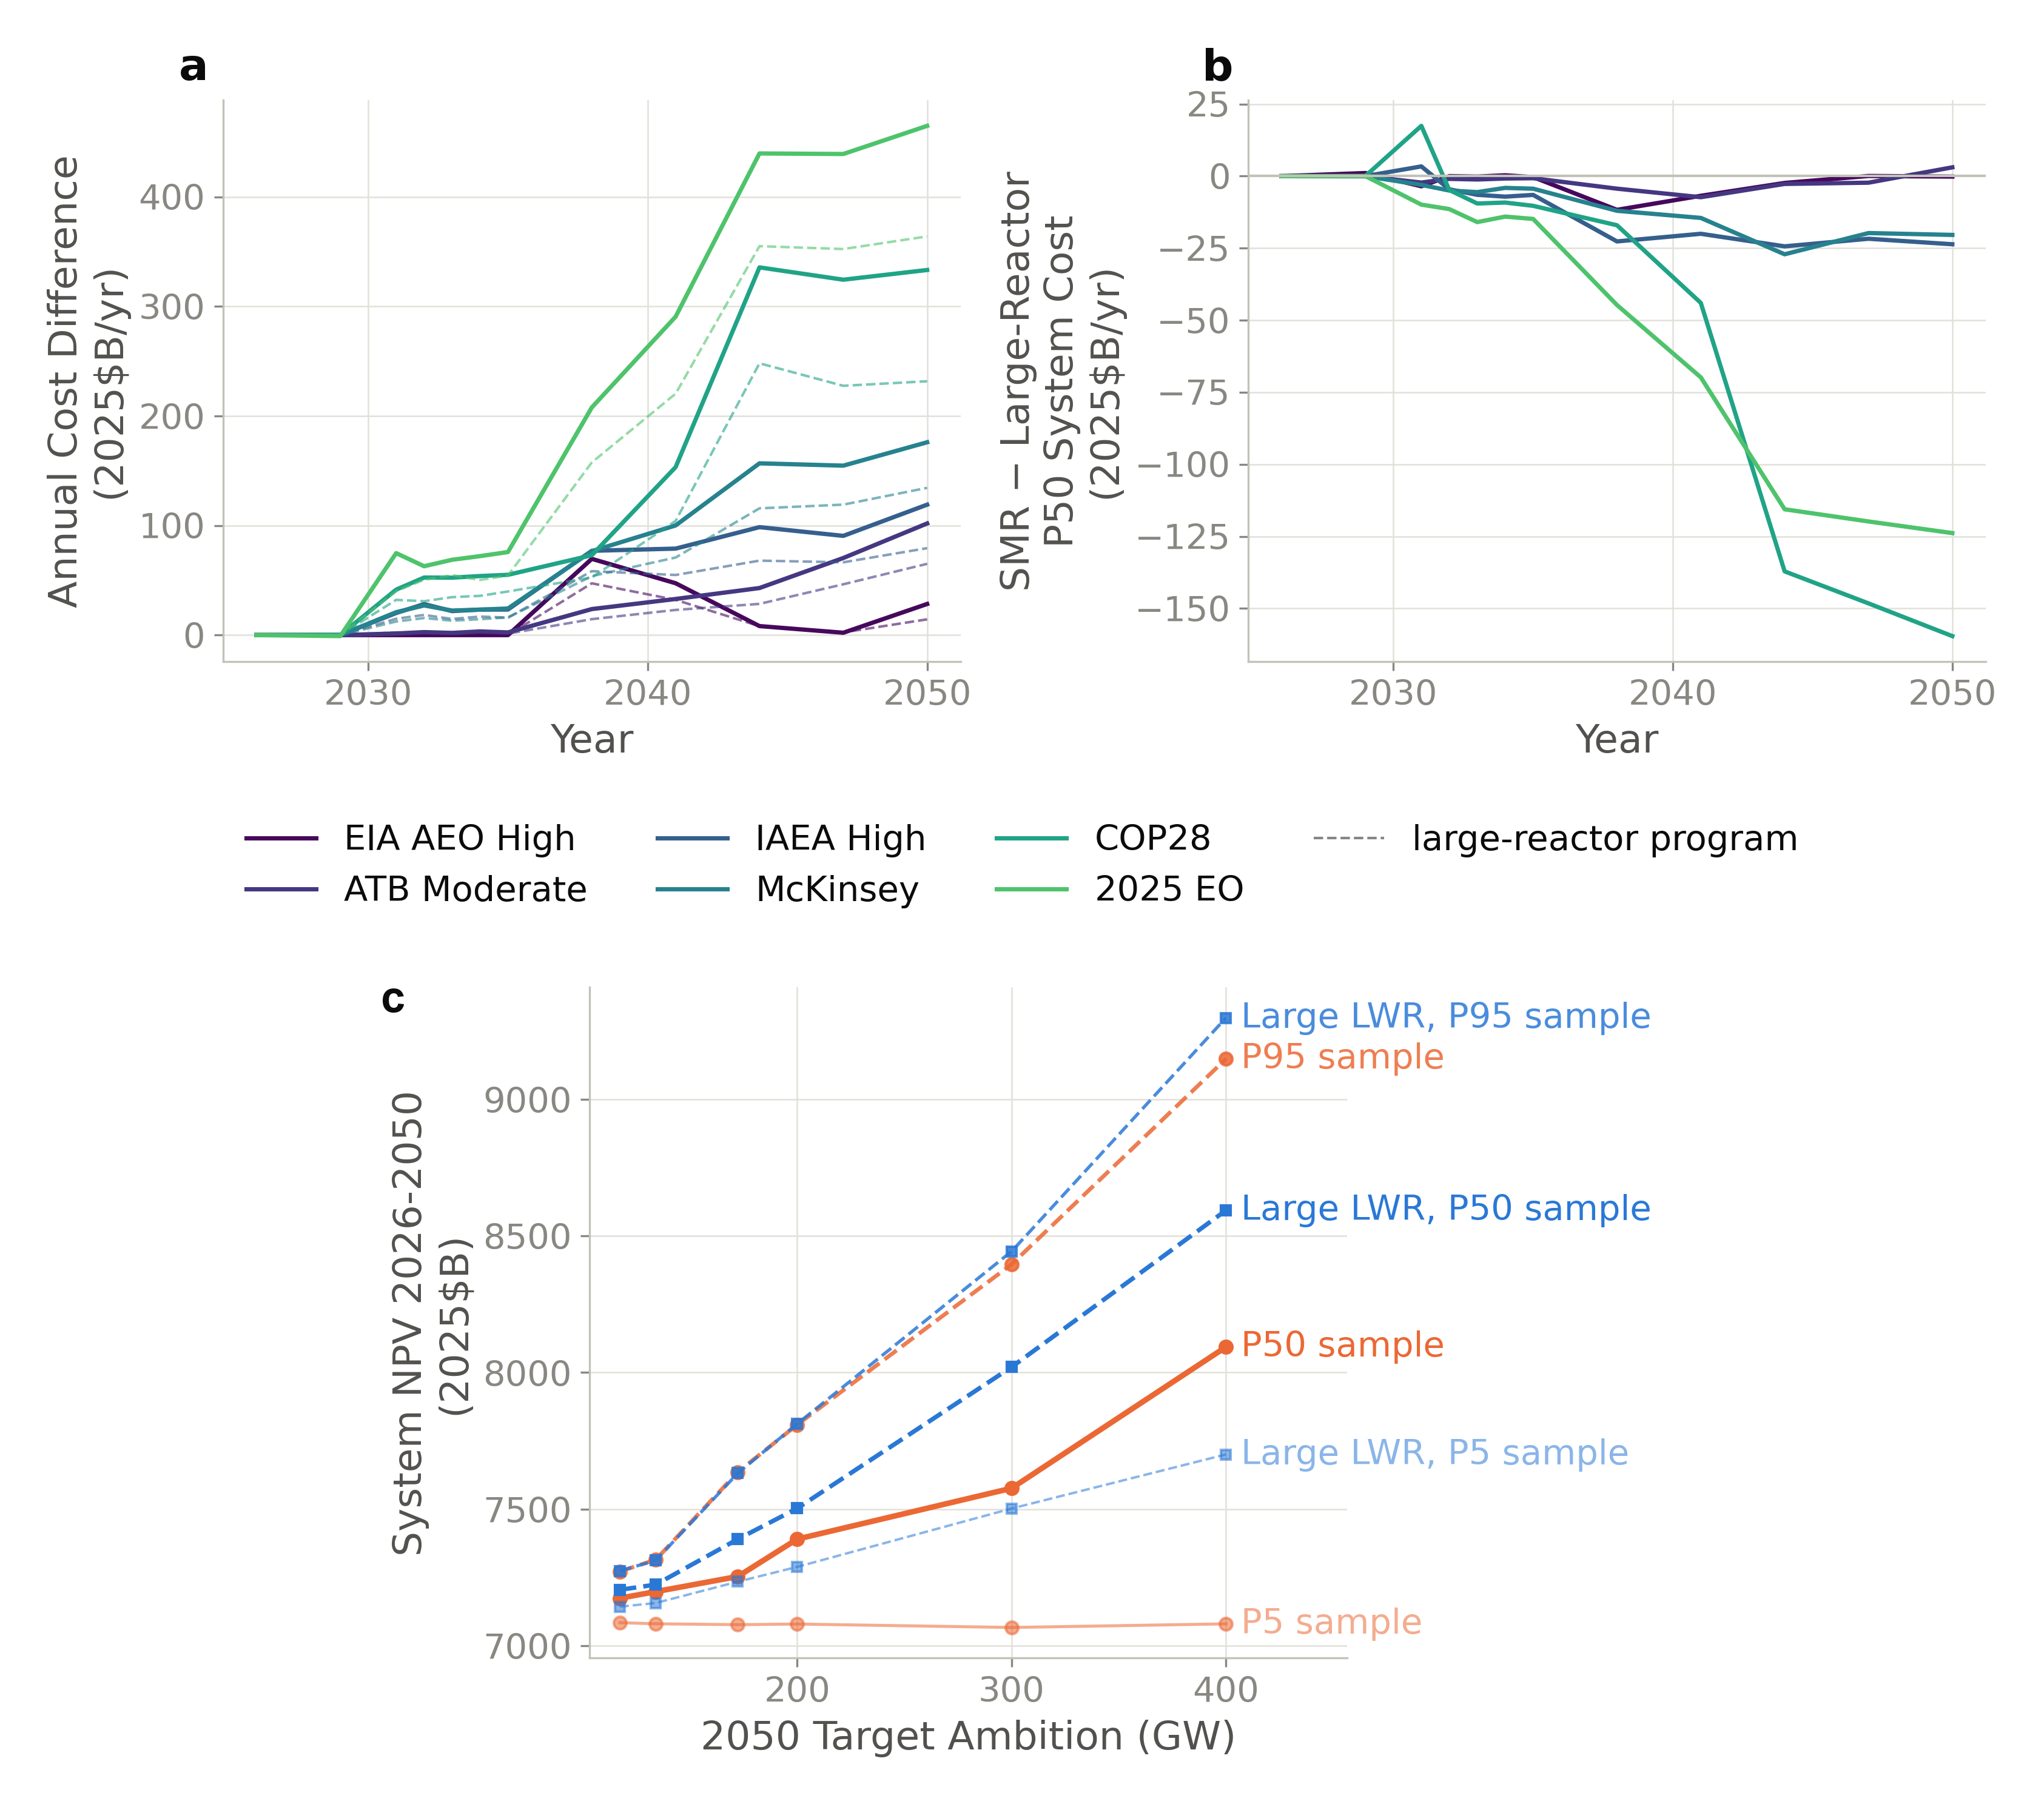

In [21]:
# ---- Supplementary Fig. 8 = f08 over f09; Supplementary Fig. 9 = f10 over f11 ----------------
from nlpaper import compose
compose.compose(
    [[FIGURES / "f08_cost_decomposition_ref.png"],
     [FIGURES / "f09_cost_totals.png"]],
    "SF08_cost_anatomy.png", out_dir=paths.FIGS_SI,
    letter_pt=ps.fonts(12.72)["panel_letter"],   # measured composite width (in)
)
_ = compose.compose(
    # stacked, one panel per row; f10 carries its own letters a and b
    [[FIGURES / "f10_within_schedule_spread.png"],
     [FIGURES / "f11_npv_vs_ambition.png"]],
    "SF09_spread_and_npv.png", out_dir=paths.FIGS_SI,
    letters=["", "c"],
    center=True,
    letter_pt=ps.fonts(11.24)["panel_letter"],
)

## 7. The rental transfer

The mandate reads as a *capacity standard with tradable capacity credits*: the constraint is on
MW standing, and the shadow price is the credit's clearing price. `t08` prices that standard by
year: the *rental transfer* R_t = shadow price(t) × program capacity(t), the implicit payment of
the mandate to all program capacity (2024 $B/yr). Its present value discounts each solve year
over its forward gap (the years to the next solve year; the 2050 gap is 1). R_t pays
inframarginal capacity as well as the marginal unit, a property of any uniform instrument.
Notebooks 10, 13a/13b and 14 read `t08`.

In [22]:
# ---- t08: rental transfer R_t ------------------------------------------------------------------
GAP = {t: (YEARS_RUN[i + 1] - t if i + 1 < len(YEARS_RUN) else 1)
       for i, t in enumerate(YEARS_RUN)}

BILL = {}      # per case: R_t Series over solve years, 2024 $B / yr
rows = []
for c in CASES:
    d = DUALS[(DUALS["case"] == c) & (DUALS["t"] >= 2026)].set_index("t").sort_index()
    # R_t pays the dual on the program's post-2030 additions; the old
    # mandate_MW basis also billed the pre-existing ~97 GW fleet that the
    # fleet-inclusive large100 mandate counts (fixed 2026-08-17). No-build
    # years are blank, not zero.
    bill = (d["dual_2004_MWyr"] * d["program_MW"] * TO2024
            / 1e9).where(d["program_MW"] > 0)
    BILL[c] = bill
    pv = sum(float(bill[t]) * GAP[t] / DR ** (t - 2026)
             for t in bill.dropna().index)
    rows.append(dict(case=c, PV_rental_transfer_2024B=round(pv, 1),
                     peak_Rt_2024B=round(float(bill.max()), 1),
                     peak_Rt_year=int(bill.idxmax()) if bill.max() > 0 else None))
t08 = pd.DataFrame(rows)
t08.to_csv(EXPORTS / "t08_rental_transfer.csv", index=False)
print(t08.to_string(index=False))

              case  PV_rental_transfer_2024B  peak_Rt_2024B  peak_Rt_year
    smr100_eia_p05                       5.0            1.7          2038
    smr100_eia_p50                      27.4            6.4          2050
    smr100_eia_p95                      49.8           12.0          2050
     smr100_aj_p05                       8.5            2.5          2050
     smr100_aj_p50                      28.6           13.4          2050
     smr100_aj_p95                      51.0           22.8          2050
   smr100_iaea_p05                      21.3            4.5          2050
   smr100_iaea_p50                      82.0           17.5          2050
   smr100_iaea_p95                     181.5           47.0          2050
    smr100_mck_p05                      21.9            4.3          2050
    smr100_mck_p50                     103.1           27.7          2050
    smr100_mck_p95                     209.6           62.6          2050
  smr100_cop28_p05                    

## 8. From the shadow price to an Equivalent ITC: the nine steps

The *Equivalent ITC* is the uniform investment-tax-credit rate that would deliver, without the
mandate, the support the mandate's shadow price says the marginal build needs. The solve is
sequential and myopic: each year's linear program prices its own builds fully, so the translation
does not discount across years. The procedure has nine steps (Supplementary Note 6):

1. **Check the baseline.** The production runs carry no nuclear credit
   (`incentives_obbba_nonuclearitc`), so `cost_cap_fin_mult` equals `cost_cap_fin_mult_noITC`
   for the mandated technology. The shadow price is then the total required support, not an
   increment on top of a credit.
2. **Read the shadow prices** per solve year. A missing table means a zero shadow price.
3. **Select the rate years.** A year enters the credit schedule only if the shadow price is
   positive, the mandate increases, and the model builds the mandated technology (`cap_new_ann`
   > 0). Without the third condition the shadow price can price the retention of an old unit, for
   which a credit on new builds is the wrong instrument (early large-reactor years). Slack years
   stay in the table with a zero requirement.
4. **Compute the required support** S_t = raw shadow price / `cost_scale` = rental price ×
   `pvf_onm`, and assert that the two agree (a units check). S_t is in 2004 $/MW: the capitalized
   cost of the marginal build minus its capitalized market value, including capital cost, fixed
   O&M and variable costs.
5. **Select the capital-cost base.** The base of a build in region r is the overnight capital
   cost `cost_cap(t)` times the region's financing multiplier. The run does not identify the
   marginal region, so the step computes one rate per building region.
6. **Invert the financing arithmetic.** ReEDS's financing multiplier (`reeds/financials.py`)
   is linear in the monetized credit fraction m: fin_mult(m) = ccmult/(1 − τ) × [1 − τ(1 − m/2)
   PV_dep − m], where τ is the tax rate, PV_dep the present value of depreciation and *ccmult*
   the construction-financing multiplier (interest during construction). Solving for m gives
   m_t(r) = S_t / (cost_cap(t) × fin_mult_noITC(r, t)) × k(t), with k = (1 − τ PV_dep) /
   (1 − τ PV_dep / 2) < 1: a credit dollar gives more than a dollar of support (tax gross-up),
   less the half-basis depreciation clawback.
7. **Assign solve years to build years.** Solve year t represents the calendar years after the
   previous solve year, through t; the rate i_t applies to all builds of that group.
8. **Compute the fiscal outputs** (section 9).
9. **Check.** The two S_t methods agree, the regional rate range is narrow, and the headline rate
   fed back into ReEDS reproduces the mandated build (notebook 09).

**Two rate conventions.** The headline is the *model-convention* rate i_model = m / (1 −
penalty): the credit applies, as in ReEDS's own arithmetic, to the invested basis OCC × ccmult,
so a credit dollar carries construction-period carrying cost (a progress payment during
construction, or a placed-in-service claim on the interest-inclusive Section 263A basis). The
*placed-in-service conversion* i_pis = i_model × ccmult is the rate of a credit written on an
overnight-cost-only basis. A real owner's statutory rate lies between the two; the table carries
both and the ccmult column.

**Monetization haircut and depreciation.** The *monetization haircut* (`itc_tax_equity_penalty`)
is the share of a credit's face value an owner loses when it sells the credit through a
tax-equity partnership or a Section 6418 transfer. The default is 0.10 (a bank tax-equity
partnership, the value in every run's incentives input). The best observed transfer terms support
0.05. Rates are linear in 1/(1 − penalty), so every rate converts to the 5 % haircut by the exact
factor (1 − 0.10)/(1 − 0.05) = 0.947 (`t20`, Supplementary Table 11e). Depreciation is 15-year
MACRS (the Modified Accelerated Cost Recovery System schedule of the runs' `financials_tech`
inputs) throughout; the instrument is hypothetical policy, so no current-law conversion is made.

**Region sufficiency.** One uniform rate must keep every building region building. The
headline rate is therefore the *maximum* of the per-region rates, the rate of the building region
with the smallest financing multiplier (`i_model_headline` = `i_model_max`). A per-region minimum
(`i_model_min`) runs about 15 % lower. Where the headline exceeds 100 %, an ITC alone cannot supply
S_t and the table flags the year (`itc_insufficient`, and `pis_insufficient` for the conversion).

The first cell replicates ReEDS's financing arithmetic (`natbase`, the region-independent part
of the multiplier, and k, ccmult) and checks it against the multipliers the runs report; the
second checks the baseline and reads the haircut; the third writes `t09` (Supplementary Table 2).

In [23]:
# ---- financing replication: natbase, PV_dep, k (procedure steps 5-6) ---------------------------
# Replicates the multiplier arithmetic of reeds/financials.py (lines 683-694).
DEP = pd.read_csv(FIN_DIR / "depreciation_schedules_default.csv")
CS = pd.read_csv(FIN_DIR / "construction_schedules_mc.csv")
# row-aligned ReEDS exponents: header 'NA' row -> 0, rows t=0..9 -> 0.5..9.5
CC_EXPS = np.append([0.0], np.arange(0.5, 10.5, 1.0))
assert len(CS) == len(CC_EXPS), (len(CS), len(CC_EXPS))

def ccmult_reeds(sched_name, ib):
    x = pd.to_numeric(CS[str(sched_name)], errors="coerce").fillna(0.0).to_numpy()
    return 1.0 + float(np.sum(x * (ib ** CC_EXPS - 1.0)))

IN_NAME = {"nuclear": "Nuclear", "nuclear-smr": "Nuclear-SMR"}

def fin_tech(case):
    fin = sw(case, "financials_tech_suffix")
    ft = pd.read_csv(FIN_DIR / f"financials_tech_{fin}.csv")
    ft.columns = [c.lstrip("*") for c in ft.columns]
    return ft[ft["i"].isin(["Nuclear", "Nuclear-SMR"])]

_NF_CACHE = {}

def natfin(case):
    """(natbase, k, ccm) Series triples on YEARS for the case's mandated technology.
    natbase = ccmult / (1 - tax) x (1 - tax x PV_dep) x risk x eval_adj — the
    r-independent part of cost_cap_fin_mult_noITC (Degradation_Adj = 1 for nuclear).
    k = (1 - tax x PV_dep) / (1 - tax x PV_dep / 2) converts the financed-cost
    ratio S / (cost_cap x fin_mult_noITC) to the monetized fraction m.
    ccm is the construction-financing multiplier; the statutory timing
    correction multiplies the rate by it."""
    key = (case, META[case]["mandated_tech"])
    if key in _NF_CACHE:
        return _NF_CACHE[key]
    grp = fin_tech(case)
    grp = grp[grp["i"] == IN_NAME[META[case]["mandated_tech"]]]
    grp = grp.set_index("t").reindex(YEARS).ffill().bfill()
    dep_col = str(int(grp["depreciation_sch"].iloc[0]))
    dep_frac = pd.to_numeric(DEP[dep_col], errors="coerce").fillna(0.0).to_numpy(float)
    pv_dep = np.array([np.sum(dep_frac / dn ** np.arange(1, len(dep_frac) + 1))
                       for dn in D_NOM])
    eval_p = float(grp["eval_period"].iloc[0])
    risk = 1.0 + grp["finance_diff_real"].to_numpy(float) * (
        (1 - (1 / D_REAL) ** eval_p) / (D_REAL - 1.0))
    sys_pvf = (1 - (1 / D_REAL) ** (30 - 1)) / (D_REAL - 1.0) + 1
    tech_pvf = (1 - (1 / D_REAL) ** (eval_p - 1)) / (D_REAL - 1.0) + 1
    eval_adj = sys_pvf / tech_pvf
    ccm = np.array([ccmult_reeds(grp.loc[t, "construction_sch"], IB[yi(t)])
                    for t in YEARS])
    natbase = pd.Series(ccm / (1 - TAX) * (1 - TAX * pv_dep) * risk * eval_adj,
                        index=YEARS)
    k = pd.Series((1 - TAX * pv_dep) / (1 - TAX * pv_dep / 2), index=YEARS)
    ccm = pd.Series(ccm, index=YEARS)
    _NF_CACHE[key] = (natbase, k, ccm)
    return natbase, k, ccm

# self-check: natbase x a time-constant regional factor reproduces the h5 multiplier.
# The time dimension makes this non-circular: it tests the time shape of natbase.
for c in ["smr100_eia_p50", "smr100_eo_p95", "large100_eo_p50", "large100_eo_p95"]:
    nb, _, _ = natfin(c)
    piv = FINMULT[c].unstack("t")
    yrs = [t for t in piv.columns if t >= 2026]
    ratio = piv[yrs].div(nb.reindex(yrs), axis=1)
    regfac = ratio.mean(axis=1)
    resid = (piv[yrs] - pd.DataFrame(np.outer(regfac, nb.reindex(yrs)),
                                     index=piv.index, columns=yrs)).abs() / piv[yrs]
    worst = float(resid.max().max())
    assert worst < 5e-3, (c, worst)
    assert 0.85 < float(regfac.min()) and float(regfac.max()) < 1.35, c
    print(f"{c}: natbase reproduces the h5 multiplier; worst rel resid {worst:.1e}; "
          f"regional factors {float(regfac.min()):.3f}..{float(regfac.max()):.3f}")

smr100_eia_p50: natbase reproduces the h5 multiplier; worst rel resid 5.9e-04; regional factors 0.953..1.254
smr100_eo_p95: natbase reproduces the h5 multiplier; worst rel resid 5.2e-04; regional factors 0.953..1.254
large100_eo_p50: natbase reproduces the h5 multiplier; worst rel resid 5.4e-04; regional factors 0.953..1.254
large100_eo_p95: natbase reproduces the h5 multiplier; worst rel resid 5.1e-04; regional factors 0.953..1.254


In [24]:
# ---- procedure step 1: baseline checks ----------------------------------------------------------
inc_no = pd.read_csv(FIN_DIR / "incentives_obbba_nonuclearitc.csv")
nuc_no = inc_no[inc_no["i"].str.upper().str.startswith("NUCLEAR")]
itc_cols = [c for c in inc_no.columns if c.startswith("itc_")]
assert float(nuc_no[itc_cols].abs().to_numpy().sum()) == 0.0, "input file has nuclear ITC"
worst_fm = max(FMDIFF.values())
assert worst_fm < 1e-9, f"fin_mult != fin_mult_noITC somewhere: {worst_fm}"
print("baseline holds: zero nuclear ITC in the incentives input; "
      "fin_mult == fin_mult_noITC for the mandated technology in all 37 runs.")
print("Thus the dual is the total required support, not an increment.")

# statutory conversion uses the OBBBA penalty for a hypothetical nuclear credit
inc_ob = pd.read_csv(FIN_DIR / "incentives_obbba.csv")
nuc_ob = inc_ob[inc_ob["i"].str.upper().str.startswith("NUCLEAR")]
PEN = float(nuc_ob["itc_tax_equity_penalty"].iloc[0])
assert (nuc_ob["itc_tax_equity_penalty"] == PEN).all()
print(f"itc_tax_equity_penalty = {PEN}; statutory i = m / (1 - {PEN})")

# haircut range (2026-08-20, open item 7a): default 0.10 = bank tax-equity
# partnership all-in cost; 0.05 = best observed transfer-market conditions
PEN_LO = 0.05
print(f"haircut range: default {PEN} (all headline numbers); best transfer-market "
      f"conditions {PEN_LO}; exact linear factor {(1 - PEN) / (1 - PEN_LO):.4f}")

baseline holds: zero nuclear ITC in the incentives input; fin_mult == fin_mult_noITC for the mandated technology in all 37 runs.
Thus the dual is the total required support, not an increment.
itc_tax_equity_penalty = 0.1; statutory i = m / (1 - 0.1)
haircut range: default 0.1 (all headline numbers); best transfer-market conditions 0.05; exact linear factor 0.9474


In [25]:
# ---- t09: required ITC rates per the procedure ---------------------------------------------------
TPREV = {t: (YEARS_RUN[i - 1] if i > 0 else None) for i, t in enumerate(YEARS_RUN)}
rate_rows = []
for c in CASES:
    tech = META[c]["mandated_tech"]
    nb, K, CCM = natfin(c)
    d = DUALS[DUALS["case"] == c].set_index("t").sort_index()
    cc, fm, bl, tr = COSTCAP[c], FINMULT[c], CAPNEW[c], TRAJ[c]
    for t in YEARS_RUN:
        if not bool(d.loc[t, "mandated"]):
            continue
        dual_pos = bool(d.loc[t, "binding"])
        m_inc = float(tr.get(t, 0.0)) - float(tr.get(TPREV[t], 0.0) if TPREV[t] else 0.0)
        blt = bl.xs(t, level="t") if t in bl.index.get_level_values("t") else pd.Series(dtype=float)
        blt = blt[blt > 0]
        if not dual_pos:
            status = "slack: required ITC is zero"
        elif m_inc <= 0:
            status = "no mandate increase: no build receives a credit"
        elif not len(blt):
            status = "no new builds: dual prices retention, not a build"
        else:
            status = "rate"
        row = dict(case=c, t=t, status=status, S_t_2004_per_MW=None, n_build_regions=0,
                   ccmult=None, i_model_min=None, i_model_max=None,
                   i_model_headline=None, i_pis_min=None, i_pis_max=None,
                   i_pis_headline=None, S_x_2p2GW_2024B=None,
                   itc_insufficient=False, pis_insufficient=False)
        if status == "rate":
            S = float(d.loc[t, "dual_raw"])                       # cost_scale = 1
            S_alt = float(d.loc[t, "dual_2004_MWyr"]) * float(PVF[c].loc[t])
            assert abs(S - S_alt) <= 1e-4 * max(1.0, abs(S)), (c, t, S, S_alt)
            fmb = fm.xs(t, level="t").reindex(blt.index).dropna()
            m_r = S / (float(cc.loc[t]) * fmb) * float(K.loc[t])  # monetized, per region
            i_r = m_r / (1.0 - PEN)   # the headline: ReEDS's credit convention
            ccm_t = float(CCM.loc[t])
            # conversion companion: placed-in-service credit on an OCC-only basis
            i_pis = i_r * ccm_t
            row.update(S_t_2004_per_MW=round(S), n_build_regions=len(i_r),
                       ccmult=round(ccm_t, 4),
                       i_model_min=round(float(i_r.min()), 3),
                       i_model_max=round(float(i_r.max()), 3),
                       i_model_headline=round(float(i_r.max()), 3),
                       i_pis_min=round(float(i_pis.min()), 3),
                       i_pis_max=round(float(i_pis.max()), 3),
                       i_pis_headline=round(float(i_pis.max()), 3),
                       # marginal-build gap on one Vogtle-pair-equivalent (2.2 GW)
                       S_x_2p2GW_2024B=round(S * 2200.0 * TO2024 / 1e9, 1),
                       itc_insufficient=bool(i_r.max() > 1.0),
                       pis_insufficient=bool(i_pis.max() > 1.0))
        rate_rows.append(row)
t09 = pd.DataFrame(rate_rows)
t09.to_csv(EXPORTS / "t09_required_itc.csv", index=False)
n_over = int(t09["itc_insufficient"].sum())
print(f"gated (case, year) points: {len(t09)}; rate rows: "
      f"{int((t09['status'] == 'rate').sum())}; model-convention rate above 100%: {n_over}")
ne9 = t09[~t09["case"].str.endswith("_eq")]     # the eq copy duplicates one world
print(f"excluding the equality duplicate: rate rows "
      f"{int((ne9['status'] == 'rate').sum())}; "
      f"above 100%: {int(ne9['itc_insufficient'].sum())} "
      f"(pis conversion: {int(ne9['pis_insufficient'].sum())})")
s9 = ne9[ne9["case"].str.startswith("smr100") & (ne9["status"] == "rate")]
print(f"smr100 only: rate rows {len(s9)}; "
      f"above 100%: {int(s9['itc_insufficient'].sum())}")
print("\nrequired ITC rate (model convention), smr100 p50:")
p50 = t09[(t09["case"].isin([f"smr100_{s}_p50" for s in SCHEDULES]))
          & (t09["status"] == "rate")]
print(p50.pivot_table(index="t", columns="case", values="i_model_headline").round(2).to_string())
print("\nconversion companion (placed-in-service, OCC-only basis), same cases:")
print(p50.pivot_table(index="t", columns="case", values="i_pis_headline").round(2).to_string())
print("\nexcluded mandated years by reason:")
print(t09[t09["status"] != "rate"].groupby("status").size().to_string())

gated (case, year) points: 496; rate rows: 444; model-convention rate above 100%: 6
excluding the equality duplicate: rate rows 439; above 100%: 6 (pis conversion: 88)
smr100 only: rate rows 274; above 100%: 3

required ITC rate (model convention), smr100 p50:
case  smr100_aj_p50  smr100_cop28_p50  smr100_eia_p50  smr100_eo_p50  smr100_iaea_p50  smr100_mck_p50
t                                                                                                    
2031           0.62              0.84             NaN           0.70             0.84            0.76
2032           0.41              0.72             NaN           0.59             0.76            0.68
2033           0.70              0.78             NaN           0.68             0.79            0.73
2034           0.65              0.73             NaN           0.65             0.75            0.69
2035           0.63              0.70             NaN           0.63             0.70            0.69
2038           0.66      

### The production tax credit, valued as an equivalent investment credit (Supplementary Table 12)

The paper never models the 45Y production tax credit (PTC). `t23` checks that omission. A
statutory ITC at rate i pays i × (1 − penalty) × cost_cap × fin_mult / k per MW, the relation `t09`
inverts. The 45Y credit pays `ptc_value` per MWh for `ptc_dur` years, carries the same haircut and
reduces no depreciable basis, so the haircut cancels and i_45Y = PV(45Y) × k / (cost_cap ×
fin_mult), with PV(45Y) = value × CF × 8760 × annuity(DR) at the full statutory value of the
runs' incentives input and a 0.91 availability factor. Both credits share the OBBBA nuclear
phase-down, which cancels. Each row is read at the region that sets the required rate. In every
priced case-year the required credit is several times the PTC's equivalent, so an owner would
elect the ITC and the PTC is never the binding ceiling.

In [26]:
# ST12 45Y equivalence (_edit_20260924_st12_ptc.py)
# ---- t23: the 45Y production tax credit valued as an equivalent investment credit ----------
# A statutory ITC at rate i pays i x (1 - PEN) x cost_cap x fin_mult / k per MW (the relation
# t09 inverts). The 45Y credit pays ptc_value per MWh for ptc_dur years, carries the same
# tax-equity haircut and reduces no depreciable basis, so the haircut cancels and
#     i_45Y = PV(45Y) x k / (cost_cap x fin_mult),  PV(45Y) = value x CF x 8760 x annuity(DR).
# Both credits share the OBBBA nuclear phase-down, so it cancels and is not applied here.
# Rows whose construction starts in 2025 or later carry the OBBBA-era 45Y value; the older
# rows carry the legacy section 45 credit, which is not the comparator.
_p45 = inc_ob[(inc_ob["ptc_value"] > 0) & (inc_ob["t_start_construction"] >= 2025)]
assert float(nuc_ob["ptc_value"].abs().sum()) == 0.0, "nuclear already carries a 45Y credit"
PTC_2004_MWH = float(_p45["ptc_value"].max())          # full statutory 45Y value, 2004 $/MWh
assert abs(PTC_2004_MWH - 16.5752) < 1e-3, PTC_2004_MWH
PTC_DUR = int(_p45.loc[_p45["ptc_value"].idxmax(), "ptc_dur"])
PTC_CF = 0.91                                          # availability cap (2026-09-03 check)
PTC_BONUS = 0.20                                       # energy community + domestic content
PTC_ANNUITY = float(sum(DR ** -y for y in range(1, PTC_DUR + 1)))
PTC_PV_2004_MW = PTC_2004_MWH * PTC_CF * 8760.0 * PTC_ANNUITY
print(f"45Y: {PTC_2004_MWH:.4f} 2004$/MWh x CF {PTC_CF} x 8760 h, {PTC_DUR} years at DR "
      f"{DR:.4f} (annuity {PTC_ANNUITY:.3f}) -> "
      f"{PTC_PV_2004_MW * TO2024 / 1e3:,.0f} 2024$/kW present value")

_ptc_rows = []
for c in CASES:
    if c.endswith("_eq"):          # the equality copy duplicates one cost sample
        continue
    _, K45, CCM45 = natfin(c)
    d45 = DUALS[DUALS["case"] == c].set_index("t").sort_index()
    cc45, fm45, bl45, tr45 = COSTCAP[c], FINMULT[c], CAPNEW[c], TRAJ[c]
    _fam, _sch, _pct, _var = parse_case(c)
    for t in YEARS_RUN:
        if not bool(d45.loc[t, "mandated"]) or not bool(d45.loc[t, "binding"]):
            continue
        m_inc45 = float(tr45.get(t, 0.0)) - float(tr45.get(TPREV[t], 0.0) if TPREV[t] else 0.0)
        if m_inc45 <= 0:
            continue
        blt45 = bl45.xs(t, level="t") if t in bl45.index.get_level_values("t") else pd.Series(dtype=float)
        blt45 = blt45[blt45 > 0]
        if not len(blt45):
            continue
        S45 = float(d45.loc[t, "dual_raw"])
        fmb45 = fm45.xs(t, level="t").reindex(blt45.index).dropna()
        i_r45 = S45 / (float(cc45.loc[t]) * fmb45) * float(K45.loc[t]) / (1.0 - PEN)
        reg = i_r45.idxmax()                      # the region that sets the required rate
        i_req = float(i_r45.max())
        ccm45 = float(CCM45.loc[t])
        i_ptc = PTC_PV_2004_MW * float(K45.loc[t]) / (float(cc45.loc[t]) * float(fmb45[reg]))
        _ptc_rows.append(dict(
            case=c, schedule=_sch, target=ps.SCHED_SHORT.get(_sch, _sch),
            mandated_tech=META[c]["mandated_tech"], cost_sample=_pct, t=t,
            headline_region=reg, ccmult=round(ccm45, 4),
            required_itc_model=round(i_req, 4),
            required_itc_pis=round(i_req * ccm45, 4),
            ptc_itc_equivalent_model=round(i_ptc, 4),
            ptc_itc_equivalent_pis=round(i_ptc * ccm45, 4),
            ptc_itc_equivalent_model_bonus20=round(i_ptc * (1.0 + PTC_BONUS), 4),
            ptc_share_of_required=round(i_ptc / i_req, 4),
            required_over_ptc=round(i_req / i_ptc, 3),
            ptc_pv_2024_per_kW=round(PTC_PV_2004_MW * TO2024 / 1e3, 1),
            note=("45Y valued as an equivalent statutory investment credit on the model "
                  "basis; the 10% tax-equity haircut cancels between the two credits; the "
                  "OBBBA nuclear phase-down applies to both and is not applied here")))

t23 = pd.DataFrame(_ptc_rows)
t23.to_csv(EXPORTS / "t23_ptc_equivalence.csv", index=False)
_p50 = t23[t23["cost_sample"] == "p50"]
print(f"t23: {len(t23)} priced (case, year) points, {len(_p50)} in the median cost sample")
print(f"45Y as an equivalent investment credit, median cost samples: "
      f"{_p50['ptc_itc_equivalent_model'].min():.2f} to "
      f"{_p50['ptc_itc_equivalent_model'].max():.2f} of the model-basis cost "
      f"({_p50['ptc_itc_equivalent_model_bonus20'].min():.2f} to "
      f"{_p50['ptc_itc_equivalent_model_bonus20'].max():.2f} with the 20-point bonus stack)")
print(f"required rate {_p50['required_itc_model'].min():.2f} to "
      f"{_p50['required_itc_model'].max():.2f}; required / 45Y "
      f"{_p50['required_over_ptc'].min():.1f} to {_p50['required_over_ptc'].max():.1f}x - "
      "the investment credit dominates in every priced case-year, so 45Y is never the "
      "binding ceiling")
print(_p50.pivot_table(index="t", columns="target",
                       values="ptc_itc_equivalent_model").round(2).to_string())

45Y: 16.5752 2004$/MWh x CF 0.91 x 8760 h, 10 years at DR 1.0536 (annuity 7.589) -> 1,664 2024$/kW present value


t23: 439 priced (case, year) points, 110 in the median cost sample
45Y as an equivalent investment credit, median cost samples: 0.11 to 0.33 of the model-basis cost (0.13 to 0.40 with the 20-point bonus stack)
required rate 0.41 to 0.90; required / 45Y 2.2 to 7.4x - the investment credit dominates in every priced case-year, so 45Y is never the binding ceiling
target  2025 EO  ATB Moderate  COP28  EIA AEO High  IAEA High  McKinsey
t                                                                      
2031       0.16          0.14   0.14           NaN       0.12      0.13
2032       0.18          0.11   0.16           NaN       0.15      0.15
2033       0.19          0.15   0.18           NaN       0.16      0.16
2034       0.20          0.15   0.19           NaN       0.17      0.17
2035       0.20          0.14   0.20           NaN       0.18      0.18
2038       0.21          0.16   0.21          0.17       0.21      0.20
2041       0.22          0.16   0.22          0.18       0.22 

### Haircut range and the required-rate figure (Supplementary Table 11e, Supplementary Fig. 10)

`t20` reports each run's peak headline rate at the 10 % and the 5 % haircut. `f13` plots the
headline rate of the SMR program per solve year, P5–P95 band and P50 line per schedule, over the
30–50 % band of the Section 48E credit (base to base-plus-bonuses) and the 100 % line above which
an ITC alone cannot deliver. `f13` is Supplementary Fig. 10 on its own.

In [27]:
# ---- t20: haircut range for the quoted rates (open item 7a, resolved 2026-08-20) ---------------
# The haircut is the one legal parameter reported as a range: i is linear in 1/(1 - penalty),
# so the 5% best-transfer-market variant is the exact factor (1 - PEN)/(1 - PEN_LO) on every
# rate, ratio, and rung. Depreciation stays 15-year MACRS everywhere by convention: the
# instrument is hypothetical policy, so no current-law depreciation conversion is reported
# (simplification ruling 2026-08-20).
fac_pen = (1.0 - PEN) / (1.0 - PEN_LO)
rows20 = []
for c in CASES:
    sub = t09[(t09["case"] == c) & (t09["status"] == "rate")]
    if not len(sub):
        continue
    hi = float(sub["i_model_headline"].max())
    rows20.append(dict(case=c,
                       i_model_peak_pen10=round(hi, 3),
                       i_model_peak_pen05=round(hi * fac_pen, 3)))
t20 = pd.DataFrame(rows20)
t20.to_csv(EXPORTS / "t20_haircut_range.csv", index=False)
print(f"haircut factor (5% vs 10% haircut): {fac_pen:.4f}")
print(t20.to_string(index=False))
for fam in ("smr100", "large100"):
    f = t20[t20["case"].str.startswith(fam) & ~t20["case"].str.endswith("_eq")]
    print(f"{fam}: peak headline rate "
          f"{f['i_model_peak_pen10'].min():.2f}..{f['i_model_peak_pen10'].max():.2f} at the "
          f"10% haircut; {f['i_model_peak_pen05'].min():.2f}.."
          f"{f['i_model_peak_pen05'].max():.2f} at 5%")

haircut factor (5% vs 10% haircut): 0.9474
              case  i_model_peak_pen10  i_model_peak_pen05
    smr100_eia_p05               0.451               0.427
    smr100_eia_p50               0.704               0.667
    smr100_eia_p95               0.873               0.827
     smr100_aj_p05               0.572               0.542
     smr100_aj_p50               0.699               0.662
     smr100_aj_p95               0.900               0.853
   smr100_iaea_p05               0.560               0.531
   smr100_iaea_p50               0.844               0.800
   smr100_iaea_p95               0.895               0.848
    smr100_mck_p05               0.577               0.547
    smr100_mck_p50               0.763               0.723
    smr100_mck_p95               0.923               0.874
  smr100_cop28_p05               0.631               0.598
  smr100_cop28_p50               0.838               0.794
  smr100_cop28_p95               1.004               0.951
     smr100_e

saved -> analysis\results\exports\07\f13_required_itc.png


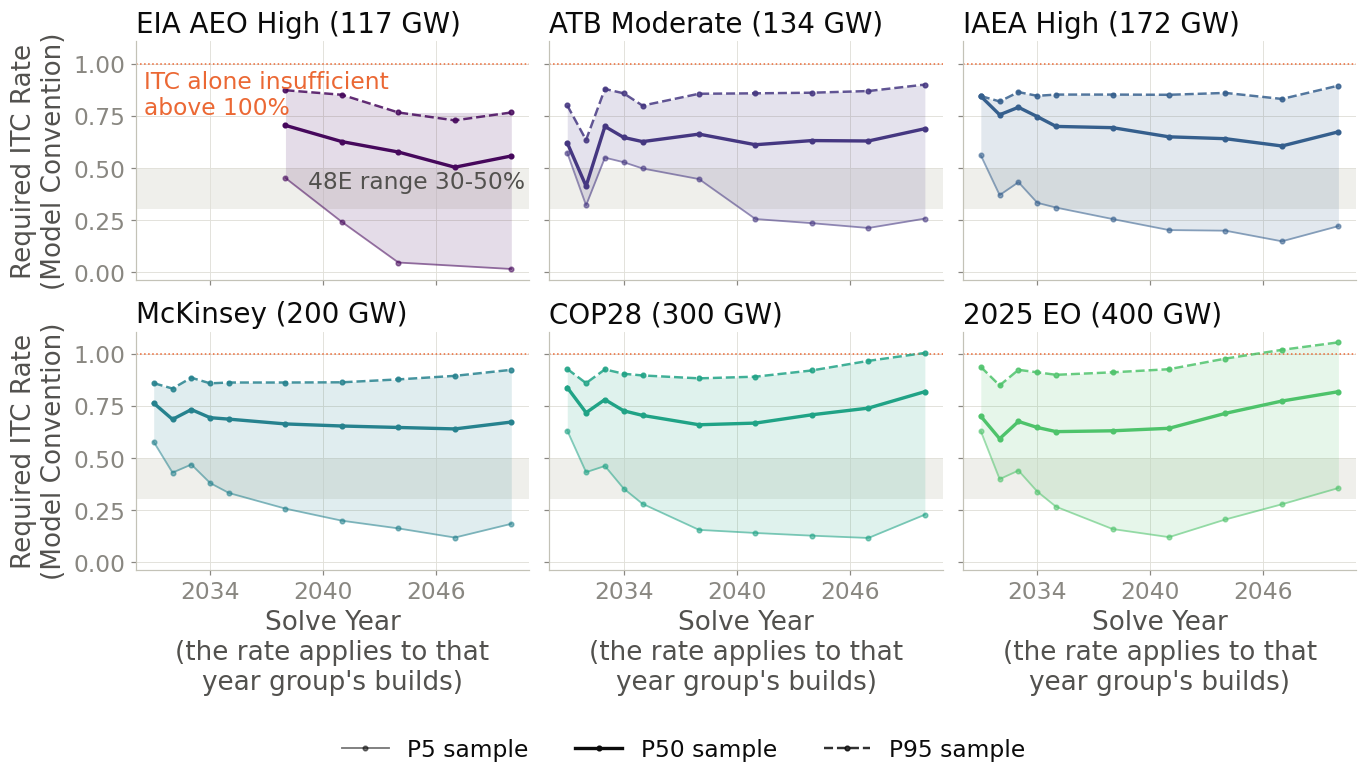

mean p50 rate as a multiple of the 30% base 48E credit: {'eia': 2.0, 'aj': 2.1, 'iaea': 2.4, 'mck': 2.3, 'cop28': 2.5, 'eo': 2.3}
same multiple in the p95 (expensive) worlds, equal prominence: {'eia': 2.7, 'aj': 2.8, 'iaea': 2.8, 'mck': 2.9, 'cop28': 3.1, 'eo': 3.1}
copied -> analysis\results\figures\si\SF10_required_credit_rate.png


In [28]:
# ---- f13: required ITC rate (model convention) against solve year ------------------------------------------
t09i = t09[t09["status"] == "rate"].set_index(["case", "t"])["i_model_headline"]

def _rate(case):
    """Per-year rate series for one case; empty if no year of that case reached 'rate' status."""
    if case in t09i.index.get_level_values("case"):
        return t09i.loc[case].sort_index()
    return pd.Series(dtype=float)

# 09-24 (Ethan E11): Supplementary Fig. 10. The Supplementary places this figure on its
# own, 12.42 in wide at 6.5 in, so the type authors at ps.fonts(12.42) and PRINTS at
# plotstyle.PAPER_FONT.
_PF = ps.fonts(12.42)
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.5), sharex=True, sharey=True)
mult = {}
for k, s in enumerate(SCHEDULES):
    ax = axes.flat[k]
    ax.axhspan(0.30, 0.50, color=GRID_C, alpha=0.5, lw=0, zorder=0)
    ax.axhline(1.0, color=COL["smr"], lw=1.0, ls=":")
    r = {p: _rate(f"smr100_{s}_{p}") for p in ("p05", "p50", "p95")}
    band = sorted(set(r["p05"].index) & set(r["p95"].index))
    if band:
        ax.fill_between(band, r["p05"][band], r["p95"][band], color=SCHED_C[s],
                        alpha=0.14, lw=0)
    for p in ("p05", "p50", "p95"):
        if not r[p].empty:
            ax.plot(r[p].index, r[p].values, color=SCHED_C[s], marker="o", ms=3.0,
                    **PCT_STYLE[p])
    # 09-24: ps.SCHED_LABEL is the plot authority for the target-trajectory names.
    ax.set_title(ps.SCHED_LABEL[s], fontsize=_PF["panel_title"])
    ax.tick_params(labelsize=_PF["tick"])
    if k % 3 == 0:
        ax.set_ylabel("Required ITC Rate\n(Model Convention)",
                      fontsize=_PF["axis_label"])
    if k >= 3:
        # three lines: at the printed size one line of this label is nearly twice as
        # wide as the panel it belongs to, and the three copies ran into each other
        ax.set_xlabel("Solve Year\n(the rate applies to that\nyear group's builds)",
                      fontsize=_PF["axis_label"])
    mult[s] = round(float(r["p50"].mean()) / 0.30, 1)
ax0 = axes.flat[0]
ax0.text(0.99, 0.40, "48E range 30-50%", fontsize=_PF["annotation"], color=MUTED,
         ha="right", transform=ax0.get_yaxis_transform())
ax0.text(0.02, 0.97, "ITC alone insufficient\nabove 100%", fontsize=_PF["annotation"],
         color=COL["smr"], ha="left", va="top",
         transform=ax0.get_yaxis_transform())
ax0.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=4, integer=True))
fig.tight_layout()
# 09-24: the key is a figure legend under the grid; inside the first panel at the
# printed size it covered that panel's tick labels and the note above.
fig.legend([mpl.lines.Line2D([], [], color=INK, marker="o", ms=3.0, **PCT_STYLE[p])
            for p in ("p05", "p50", "p95")],
           [PCT_LABEL[p] for p in ("p05", "p50", "p95")],
           fontsize=_PF["legend"], ncols=3,
           loc="upper center", bbox_to_anchor=(0.5, -0.01), frameon=False)
savefig(fig, "f13_required_itc.png")
plt.show()
print("mean p50 rate as a multiple of the 30% base 48E credit:", mult)
p95m = {s: round(float(t09i.loc[f'smr100_{s}_p95'].mean()) / 0.30, 1) for s in SCHEDULES}
print("same multiple in the p95 (expensive) worlds, equal prominence:", p95m)
# Supplementary Fig. 10 is this panel on its own
shutil.copyfile(FIGURES / "f13_required_itc.png", paths.FIGS_SI / "SF10_required_credit_rate.png")
print(f"copied -> {paths.rel(paths.FIGS_SI / 'SF10_required_credit_rate.png')}")

## 9. Fiscal outputs: the credit outlay, the floor, and the rate resolution (Supplementary Table 11)

**Credit outlay (`t10`).** B_t = i_model(t) × ccmult(t) × Σ over building regions of (capital-cost
base × builds): the credit's face value accrued to commissioning. ccmult accrues at
`interest_rate_nom` (8.0 % nominal) and the ledger's after-tax nominal cost of capital is 7.99 %,
so the timing of payment is present-value neutral and there is no separate counterfactual outlay.
The capital-cost base per MW in region r is cost_cap(t) × the regional factor (the reported
multiplier over `natbase`). The PV weights sum the discount factors of the calendar years each
solve year represents.

**Fiscal comparison (`t12`).** The present value of the credit outlay beside the present value of
the rental transfer `t08`: two different objects (a credit on new builds; an implicit payment to
all program capacity). Notebooks 10 and 14 read `t12`.

**Companion value (`t11`).** For each rate year b, C_b is the discounted sum of the rental price
over the build's 30-year evaluation window: the support an investor with full foresight of the
realized shadow-price path would require. The window runs past 2050, so C_b is bracketed by two
conventions: **cut** (zero after 2050) and **hold** (the 2050 value continues). The hold value at
2050 reproduces S_2050 (asserted through the printed ratio). `t11` feeds the commitment columns of
`t13` and `t19`.

**Floor, grant and credit, net of tax (`t13`).** Every instrument is scored through ReEDS's own
financing arithmetic (symmetric scoring). The *floor* is the minimum net government cost that
delivers S_t to every build: floor = (1 − τ) × T / (risk × eval_adj), with T = Σ S_t × builds, risk
the technology hurdle premium inside the multiplier and eval_adj = 1 here. The cell checks the
premise from the runs' `reduced_cost`: no building region carries a nonzero reduced cost, so every
builder's gap equals S_t. The credit's net cost is N = B × (1 − τ PV_dep / 2), and the identity
N / floor = capex overshoot / (1 − penalty) holds (asserted). The credit's excess over the floor is
two frictions: the monetization haircut, and the *uniform-rate overshoot* (`capex_overshoot`, the
build-weighted ratio of each region's multiplier to the smallest), because a percentage of
heterogeneous capital-cost bases pays the cheapest base's rate to every costlier base.

**Rate resolution (`t14`).** One rate per geography per year: federal (the headline, identical to
`t10`, asserted), per state (`inputs/zones/z90/hierarchy.csv`) and per zone; finer resolution saves
only the part of the overshoot inside each geography.

**Commitment ITC (`t19`).** C_b pushed through the same inversion as S_t: the rate schedule a
foresighted investor accepts under a credible declining path, bracketed by cut and hold.

In [29]:
# ---- t10: ITC outlay B_t ------------------------------------------------------------------------
out_rows = []
for c in CASES:
    nb, K, CCM = natfin(c)
    cc, fm, bl = COSTCAP[c], FINMULT[c], CAPNEW[c]
    sub = t09[(t09["case"] == c) & (t09["status"] == "rate")].set_index("t")
    for t in sub.index:
        i_head = float(sub.loc[t, "i_model_headline"])
        ccm_t = float(CCM.loc[t])
        blt = bl.xs(t, level="t")
        blt = blt[blt > 0]
        fmb = fm.xs(t, level="t").reindex(blt.index)
        base = float(cc.loc[t]) * fmb / float(nb.loc[t])          # OCC x regfac, 2004$/MW
        B_ann = i_head * ccm_t * float((base * blt).sum())  # face accrued to commissioning
        # timing-neutrality invariance: identical to the old statutory booking
        # i_pis x base, up to the 3-dp rounding of both rates in t09
        assert (abs(i_head * ccm_t - float(sub.loc[t, "i_pis_headline"]))
                <= 5.5e-4 * (1.0 + ccm_t)), (c, t)
        bgap = t - TPREV[t]
        pv_w = sum(1.0 / DR ** (y - 2026) for y in range(t - bgap + 1, t + 1))
        out_rows.append(dict(case=c, t=t, i_model_headline=i_head,
                             B_t_2024B_per_yr=round(B_ann * TO2024 / 1e9, 2),
                             PV_weight_years=bgap, _pv_2004=B_ann * pv_w))
t10 = pd.DataFrame(out_rows)
pv_case = (t10.groupby("case")["_pv_2004"].sum() * TO2024 / 1e9).round(1)
t10 = t10.drop(columns="_pv_2004")
t10.to_csv(EXPORTS / "t10_itc_outlay.csv", index=False)
cmp_tbl = pd.DataFrame({"PV_ITC_outlay_2024B": pv_case,
                        "PV_rental_transfer_2024B":
                            t08.set_index("case")["PV_rental_transfer_2024B"]})
cmp_tbl["outlay_over_rental"] = (cmp_tbl["PV_ITC_outlay_2024B"]
                                 / cmp_tbl["PV_rental_transfer_2024B"]).round(2)
cmp_tbl.to_csv(EXPORTS / "t12_fiscal_comparison.csv")
print("PV of the two fiscal quantities, 2026-2050, 2024 $B (B_t accrued to commissioning):")
print(cmp_tbl.to_string())

PV of the two fiscal quantities, 2026-2050, 2024 $B (B_t accrued to commissioning):
                    PV_ITC_outlay_2024B  PV_rental_transfer_2024B  outlay_over_rental
case                                                                                 
large100_aj_p05                    53.6                      20.5                2.61
large100_aj_p50                    88.5                      34.4                2.57
large100_aj_p95                   126.1                      50.1                2.52
large100_cop28_p05                269.6                     126.9                2.12
large100_cop28_p50                512.5                     256.2                2.00
large100_cop28_p95                749.2                     379.8                1.97
large100_eia_p05                   38.2                      19.3                1.98
large100_eia_p50                   63.0                      33.9                1.86
large100_eia_p95                   86.8                 

In [30]:
# ---- t11: companion value C_b with the post-2050 cut/hold band ------------------------------------
EVAL_W = 30      # years; eval_period of both techs (financials_tech input)
# window discount rate = post-2026 system real rate; ordinary-annuity indexing
# (year b+j discounted by DRW^(j+1)) matches the ReEDS pvf_onm = 1/crf arithmetic.
DRW = float(np.mean(D_REAL[YEARS >= 2026]))
assert abs(DRW - DR) < 1e-12, (DRW, DR)   # 2026-09-22: one rate for windows and the ledger
ann30 = sum(DRW ** -k for k in range(1, EVAL_W + 1))
pvf_run = float(PVF[REF].loc[2050])
assert abs(ann30 - pvf_run) / pvf_run < 0.01, (ann30, pvf_run)
print(f"window annuity at DRW={DRW - 1:.4%}: {ann30:.4f}; run pvf_onm(2050): {pvf_run:.4f}")

wed_rows = []
for c in CASES:
    d = DUALS[DUALS["case"] == c].set_index("t")["dual_2004_MWyr"].sort_index()
    d2050 = float(d.get(2050, 0.0))
    sub = t09[(t09["case"] == c) & (t09["status"] == "rate")].set_index("t")
    for b in sub.index:
        S = float(sub.loc[b, "S_t_2004_per_MW"])
        c_cut, c_hold = 0.0, 0.0
        for j in range(EVAL_W):
            y = b + j
            w = DRW ** -(j + 1)
            if y <= 2050:
                v = float(d.get(year_rep(y), 0.0))
                c_cut += v * w
                c_hold += v * w
            else:
                c_hold += d2050 * w
        wed_rows.append(dict(case=c, t=b, S_t_2004_per_MW=round(S),
                             C_cut_2004_per_MW=round(c_cut),
                             C_hold_2004_per_MW=round(c_hold),
                             cut_over_S=round(c_cut / S, 2),
                             hold_over_S=round(c_hold / S, 2),
                             tail_share_of_hold=round(1 - c_cut / c_hold, 2)
                                                if c_hold > 0 else 0.0))
t11 = pd.DataFrame(wed_rows)
t11.to_csv(EXPORTS / "t11_myopia_wedge.csv", index=False)

r = t11[t11["case"].str.startswith("smr100")]
early = r[r["t"] <= 2041]
print("hold / myopic ratio, smr100: "
      f"{r['hold_over_S'].min():.2f} .. {r['hold_over_S'].max():.2f} "
      f"(builds through 2041: {early['hold_over_S'].min():.2f} .. "
      f"{early['hold_over_S'].max():.2f})")
late = r[r["t"] == 2050]
print("hold / S at 2050 (identity check, expect near 1): "
      f"{late['hold_over_S'].min():.2f} .. {late['hold_over_S'].max():.2f}")
print("post-2050 tail share of C_hold at 2050 builds: "
      f"{late['tail_share_of_hold'].min():.2f} .. {late['tail_share_of_hold'].max():.2f}")

window annuity at DRW=5.3585%: 14.7637; run pvf_onm(2050): 14.7645


hold / myopic ratio, smr100: 0.23 .. 1.82 (builds through 2041: 0.23 .. 1.82)
hold / S at 2050 (identity check, expect near 1): 1.00 .. 1.00
post-2050 tail share of C_hold at 2050 builds: 0.94 .. 0.94


In [31]:
# ---- t13: floor, flat grant, and ITC — net-of-tax government cost (symmetric scoring) ----------
rows13 = []
cw_all = t11.set_index(["case", "t"])
for c in CASES:
    tech = META[c]["mandated_tech"]
    bl = CAPNEW[c]
    # LP optimality: no building (r, t) carries a reduced-cost row (zeros are suppressed)
    rc = load(c, "reduced_cost")
    rc = rc[(rc["i"] == tech) & (rc["*.1"] == "cap")]
    builders = set(zip(bl[bl > 0].index.get_level_values("r"),
                       bl[bl > 0].index.get_level_values("t")))
    overlap = builders & set(zip(rc["r"], rc["t"]))
    assert not overlap, (c, sorted(overlap)[:5])
    nbse, K, CCM = natfin(c)
    cc, fm = COSTCAP[c], FINMULT[c]
    # the technology hurdle premium inside fin_mult_noITC (same arithmetic as natfin)
    g46 = fin_tech(c)
    g46 = g46[g46["i"] == IN_NAME[tech]].set_index("t").reindex(YEARS).ffill().bfill()
    ev46 = float(g46["eval_period"].iloc[0])
    rk46 = pd.Series(1.0 + g46["finance_diff_real"].to_numpy(float)
                     * ((1 - (1 / D_REAL) ** ev46) / (D_REAL - 1.0)), index=YEARS)
    sub = t09[(t09["case"] == c) & (t09["status"] == "rate")].set_index("t")
    pv = dict(T=0.0, T_net=0.0, FLOOR=0.0, B=0.0, N=0.0, OV=0.0, RK=0.0, PRED=0.0,
              COM_cut=0.0, COM_hold=0.0)
    for t in sub.index:
        S = float(sub.loc[t, "S_t_2004_per_MW"])
        i_head = float(sub.loc[t, "i_model_headline"])
        ccm_t = float(CCM.loc[t])
        blt = bl.xs(t, level="t")
        blt = blt[blt > 0]
        fmb = fm.xs(t, level="t").reindex(blt.index)
        base = float(cc.loc[t]) * fmb / float(nbse.loc[t])     # OCC x regfac, 2004$/MW
        B_ann = i_head * ccm_t * float((base * blt).sum())     # face accrued to commissioning
        tau = float(TAX[yi(t)])
        k_t = float(K.loc[t])
        claw = 1.0 / (2.0 - k_t)                    # 1 - tau*PV_dep/2 (dep-basis clawback)
        rk_t = float(rk46.loc[t])
        bgap = t - TPREV[t]
        pv_w = sum(1.0 / DR ** (y - 2026) for y in range(t - bgap + 1, t + 1))
        pv["T"] += S * float(blt.sum()) * pv_w
        pv["T_net"] += S * float(blt.sum()) * (1.0 - tau) * pv_w
        # the floor: commissioning-date cash scored through the same financing
        # machinery as the credit (symmetric scoring, 2026-08-18)
        w_fl = S * float(blt.sum()) * (1.0 - tau) / rk_t * pv_w
        pv["FLOOR"] += w_fl
        pv["B"] += B_ann * pv_w
        pv["N"] += B_ann * claw * pv_w
        # net-ratio identity terms, floor-PV-weighted
        ov_t = float((fmb * blt).sum() / (fmb.min() * float(blt.sum())))
        pv["OV"] += ov_t * w_fl
        pv["RK"] += rk_t * w_fl
        pv["PRED"] += ov_t / (1.0 - PEN) * w_fl
        # commitment bound: the same accumulation with C_b in place of S_t
        pv["COM_cut"] += (float(cw_all.loc[(c, t), "C_cut_2004_per_MW"])
                          * float(blt.sum()) * (1.0 - tau) / rk_t * pv_w)
        pv["COM_hold"] += (float(cw_all.loc[(c, t), "C_hold_2004_per_MW"])
                           * float(blt.sum()) * (1.0 - tau) / rk_t * pv_w)
    v = {k_: pv[k_] * TO2024 / 1e9
         for k_ in ("T", "T_net", "FLOOR", "B", "N", "COM_cut", "COM_hold")}
    ov_w = pv["OV"] / pv["FLOOR"]
    rk_w = pv["RK"] / pv["FLOOR"]
    pred = pv["PRED"] / pv["FLOOR"]
    # identity: net ratio vs floor = overshoot / (1 - penalty); the risk/eval
    # leverage cancels between instrument and floor, and the tax terms cancel
    # exactly (k x claw = 1 - tau x PV_dep). tolerance 5e-3: B uses the
    # 3-dp-rounded i_model_headline from t09 (exact when unrounded).
    assert abs(pred - v["N"] / v["FLOOR"]) < 5e-3, (c, pred, v["N"] / v["FLOOR"])
    assert abs(v["B"] - float(cmp_tbl.loc[c, "PV_ITC_outlay_2024B"])) <= max(0.06, 5e-3 * v["B"])
    rows13.append(dict(case=c,
                       PV_flat_grant_2024B=round(v["T"], 1),
                       PV_grant_net_2024B=round(v["T_net"], 1),
                       PV_floor_2024B=round(v["FLOOR"], 1),
                       PV_ITC_outlay_2024B=round(v["B"], 1),
                       PV_ITC_net_2024B=round(v["N"], 1),
                       PV_commit_cut_2024B=round(v["COM_cut"], 1),
                       PV_commit_hold_2024B=round(v["COM_hold"], 1),
                       net_ratio_vs_floor=round(v["N"] / v["FLOOR"], 2),
                       net_ratio_vs_grant=round(v["N"] / v["T_net"], 2),
                       gross_scoring_ratio=round(v["B"] / v["T"], 2),
                       capex_overshoot=round(ov_w, 4),
                       risk_premium_factor=round(rk_w, 4),
                       pred_net_ratio=round(pred, 4)))
t13 = pd.DataFrame(rows13)
t13.to_csv(EXPORTS / "t13_flat_grant.csv", index=False)
print("reduced-cost check: no building (r, t) has a nonzero reduced cost, in any "
      "case (LP optimality at basic builds; see the markdown note above).")
print(t13.to_string(index=False))
for fam in ("smr100", "large100"):
    f = t13[t13["case"].str.startswith(fam)]
    print(f"\n{fam}  net vs floor: "
          f"{f['net_ratio_vs_floor'].min():.2f} .. {f['net_ratio_vs_floor'].max():.2f}"
          f";  net vs flat grant: {f['net_ratio_vs_grant'].min():.2f} .. "
          f"{f['net_ratio_vs_grant'].max():.2f}"
          f";  gross scoring B/T: {f['gross_scoring_ratio'].min():.2f} .. "
          f"{f['gross_scoring_ratio'].max():.2f}")

reduced-cost check: no building (r, t) has a nonzero reduced cost, in any case (LP optimality at basic builds; see the markdown note above).
              case  PV_flat_grant_2024B  PV_grant_net_2024B  PV_floor_2024B  PV_ITC_outlay_2024B  PV_ITC_net_2024B  PV_commit_cut_2024B  PV_commit_hold_2024B  net_ratio_vs_floor  net_ratio_vs_grant  gross_scoring_ratio  capex_overshoot  risk_premium_factor  pred_net_ratio
    smr100_eia_p05                 18.5                13.7            13.2                 17.8              16.5                  3.4                   3.6                1.25                1.20                 0.96           1.1274               1.0426          1.2527
    smr100_eia_p50                 55.3                41.1            39.4                 52.3              48.4                 18.6                  34.3                1.23                1.18                 0.95           1.1054               1.0426          1.2282
    smr100_eia_p95                 97.3 

In [32]:
# ---- t14: ITC outlay by rate resolution (federal / state / zone) -------------------------------
R2ST = pd.read_csv(INPUTS / "zones" / "z90" / "hierarchy.csv").set_index("r")["st"]
rows14 = []
for c in CASES:
    nbse, K, CCM = natfin(c)
    cc, fm, bl = COSTCAP[c], FINMULT[c], CAPNEW[c]
    sub = t09[(t09["case"] == c) & (t09["status"] == "rate")].set_index("t")
    pv = dict(fed=0.0, state=0.0, zone=0.0)
    for t in sub.index:
        S = float(sub.loc[t, "S_t_2004_per_MW"])
        blt = bl.xs(t, level="t")
        blt = blt[blt > 0]
        fmb = fm.xs(t, level="t").reindex(blt.index)
        FC = float(cc.loc[t]) * fmb
        i_need = (S * float(K.loc[t])
                  / ((1.0 - PEN) * FC))     # model-convention rate that delivers S_t in r
        cost = (FC / float(nbse.loc[t]) * blt
                * float(CCM.loc[t]))    # capex base x builds, accrued to commissioning
        st = R2ST.reindex(blt.index)
        assert not st.isna().any(), (c, t, list(blt.index[st.isna()]))
        bgap = t - TPREV[t]
        pv_w = sum(1.0 / DR ** (y - 2026) for y in range(t - bgap + 1, t + 1))
        pv["fed"] += float(i_need.max()) * float(cost.sum()) * pv_w
        pv["state"] += float((i_need.groupby(st).transform("max") * cost).sum()) * pv_w
        pv["zone"] += float((i_need * cost).sum()) * pv_w
    fed, stt, zn = (pv[k_] * TO2024 / 1e9 for k_ in ("fed", "state", "zone"))
    B_head = float(cmp_tbl.loc[c, "PV_ITC_outlay_2024B"])
    assert abs(fed - B_head) <= max(0.06, 5e-3 * B_head), (c, fed, B_head)
    rows14.append(dict(case=c, PV_fed_2024B=round(fed, 1), PV_state_2024B=round(stt, 1),
                       PV_zone_2024B=round(zn, 1),
                       state_saving=round(1.0 - stt / fed, 3),
                       zone_saving=round(1.0 - zn / fed, 3)))
t14 = pd.DataFrame(rows14)
t14.to_csv(EXPORTS / "t14_itc_resolution.csv", index=False)
print("federal rung reproduces the t10 headline outlay in every case (asserted).")
print(t14.to_string(index=False))
for fam in ("smr100", "large100"):
    f = t14[t14["case"].str.startswith(fam)]
    print(f"\n{fam}  state saving: {100 * f['state_saving'].min():.0f} .. "
          f"{100 * f['state_saving'].max():.0f} %;  zone adds at most "
          f"{100 * (f['zone_saving'] - f['state_saving']).max():.1f} points")

federal rung reproduces the t10 headline outlay in every case (asserted).
              case  PV_fed_2024B  PV_state_2024B  PV_zone_2024B  state_saving  zone_saving
    smr100_eia_p05          17.8            15.8           15.8         0.111        0.113
    smr100_eia_p50          52.3            47.3           47.3         0.095        0.095
    smr100_eia_p95          87.8            83.2           83.2         0.052        0.052
     smr100_aj_p05          22.8            20.7           20.7         0.089        0.092
     smr100_aj_p50          74.0            67.1           67.1         0.092        0.093
     smr100_aj_p95         127.4           119.4          119.0         0.063        0.066
   smr100_iaea_p05          49.8            46.0           45.8         0.077        0.080
   smr100_iaea_p50         166.0           153.4          153.1         0.076        0.078
   smr100_iaea_p95         310.7           291.6          291.4         0.062        0.062
    smr100_mck_p

In [33]:
# ---- t19: the commitment ITC rate schedule -------------------------------------------------------
rows19 = []
cw19 = t11.set_index(["case", "t"])
for c in CASES:
    nbse, K, CCM = natfin(c)
    cc, fm, bl = COSTCAP[c], FINMULT[c], CAPNEW[c]
    sub = t09[(t09["case"] == c) & (t09["status"] == "rate")].set_index("t")
    for t in sub.index:
        blt = bl.xs(t, level="t")
        blt = blt[blt > 0]
        fmb = fm.xs(t, level="t").reindex(blt.index)
        den = (1.0 - PEN) * float(cc.loc[t]) * float(fmb.min())
        i_m = float(sub.loc[t, "i_model_headline"])
        # same inversion as t09's headline (S x K / den); sanity vs the table
        assert abs(float(sub.loc[t, "S_t_2004_per_MW"]) * float(K.loc[t]) / den
                   - i_m) < 5e-3, (c, t)
        rows19.append(dict(
            case=c, t=t,
            i_commit_cut=round(float(cw19.loc[(c, t), "C_cut_2004_per_MW"])
                               * float(K.loc[t]) / den, 3),
            i_commit_hold=round(float(cw19.loc[(c, t), "C_hold_2004_per_MW"])
                                * float(K.loc[t]) / den, 3),
            i_model_headline=i_m))
t19 = pd.DataFrame(rows19)
t19["hold_over_model"] = (t19["i_commit_hold"] / t19["i_model_headline"]).round(2)
t19.to_csv(EXPORTS / "t19_commitment_itc.csv", index=False)
f19 = t19[t19["case"].str.startswith("smr100") & t19["case"].str.endswith("_p50")]
dm = f19.groupby("case")["i_model_headline"].apply(lambda s: s.diff().abs().mean())
dc = f19.groupby("case")["i_commit_hold"].apply(lambda s: s.diff().abs().mean())
print(f"smr100 p50 mean |year-over-year rate step|: myopic {dm.mean():.3f}, "
      f"commitment-hold {dc.mean():.3f} (flatter)")
print(f"hold_over_model, smr100: {f19['hold_over_model'].min():.2f} .. "
      f"{f19['hold_over_model'].max():.2f} at p50")

smr100 p50 mean |year-over-year rate step|: myopic 0.053, commitment-hold 0.037 (flatter)
hold_over_model, smr100: 0.45 .. 1.11 at p50


## 10. Check of the Supplementary Note 6 numbers (uniform-rate overpayment)

Supplementary Note 6 quotes four numbers that were read by hand from three median-sample runs
(`smr100_aj_p50`, `smr100_mck_p50`, `smr100_eo_p50`) and marks
them for verification. This section recomputes them from the extracts and the tables above:

- **The span of the regional capital-cost multiplier among building regions.** In the note's
  algebra the financed cost of region R is OCC × r_R × F(0); the run reports the product r_R × F(0)
  as `cost_cap_fin_mult_noITC(r, t)`. The span is its minimum and maximum over the building
  regions of every rate year. The regional factor alone (the multiplier over `natbase`) is printed
  beside it.
- **The capacity-weighted overpayment, in rate points, by online year.** At the headline rate i*
  region R is overpaid by i* × (1 − r_min / r_R) rate points; the build-weighted mean over the
  building regions of each rate year, then the range over years.
- **The most-overpaid region's excess**, the largest i* × (1 − r_min / r_R) over regions and
  years, which equals the spread `i_model_headline − i_model_min` of `t09`.
- **The ratio of credit outlay to the sum of regional gaps**, the `t13` capex overshoot (build-
  and PV-weighted), reported as a percentage excess.

The cell prints the comparison with the note's 1.24–1.63 / 0.8–7.3 points / 15.9–19.6 points /
8–10 %. It changes nothing if they differ.

In [34]:
# ---- SN6 check: the uniform-rate overpayment of three median-sample runs ------------------------
SN6_CASES = ["smr100_aj_p50", "smr100_mck_p50", "smr100_eo_p50"]
# the hand-read values that Supplementary Note 6 quotes
SN6_SI = {"smr100_aj_p50":  dict(cw_lo=0.8, cw_hi=7.0, max_pts=15.9, outlay_excess_pct=10),
          "smr100_mck_p50": dict(cw_lo=3.2, cw_hi=7.3, max_pts=15.9, outlay_excess_pct=9),
          "smr100_eo_p50":  dict(cw_lo=3.2, cw_hi=6.4, max_pts=19.6, outlay_excess_pct=8)}
SN6_SI_MULT = (1.24, 1.63)
t13i = t13.set_index("case")
rows_y = []
for c in SN6_CASES:
    nbse, K, CCM = natfin(c)
    fm, bl = FINMULT[c], CAPNEW[c]
    sub = t09[(t09["case"] == c) & (t09["status"] == "rate")].set_index("t")
    for t in sub.index:
        blt = bl.xs(t, level="t")
        blt = blt[blt > 0]
        fmb = fm.xs(t, level="t").reindex(blt.index)      # r_R x F(0) per building region
        allr = fm.xs(t, level="t")                          # every region of the run
        i_star = float(sub.loc[t, "i_model_headline"])
        over_pts = 100.0 * i_star * (1.0 - float(fmb.min()) / fmb)
        # the largest excess is the t09 spread headline - per-region minimum (3-dp rounding)
        spread = 100.0 * (i_star - float(sub.loc[t, "i_model_min"]))
        assert abs(float(over_pts.max()) - spread) < 0.15, (c, t, float(over_pts.max()), spread)
        regf = fmb / float(nbse.loc[t])
        rows_y.append(dict(
            case=c, t=int(t), n_build_regions=len(blt), i_model_headline=i_star,
            fin_mult_min_build=round(float(fmb.min()), 4), fin_mult_max_build=round(float(fmb.max()), 4),
            fin_mult_min_all=round(float(allr.min()), 4), fin_mult_max_all=round(float(allr.max()), 4),
            regfac_min_build=round(float(regf.min()), 4), regfac_max_build=round(float(regf.max()), 4),
            overpay_cw_pts=round(float((over_pts * blt).sum() / blt.sum()), 2),
            overpay_max_pts=round(float(over_pts.max()), 2),
            overpay_max_region=str(over_pts.idxmax())))
sn6y = pd.DataFrame(rows_y)
sn6y.to_csv(EXPORTS / "sn6_uniform_rate_by_year.csv", index=False)

rows_c = []
for c in SN6_CASES:
    y = sn6y[sn6y["case"] == c]
    si = SN6_SI[c]
    ov = float(t13i.loc[c, "capex_overshoot"])
    rows_c.append(dict(
        case=c, n_rate_years=len(y),
        fin_mult_min_build=float(y["fin_mult_min_build"].min()),
        fin_mult_max_build=float(y["fin_mult_max_build"].max()),
        regfac_min_build=float(y["regfac_min_build"].min()),
        regfac_max_build=float(y["regfac_max_build"].max()),
        overpay_cw_min_pts=float(y["overpay_cw_pts"].min()),
        overpay_cw_max_pts=float(y["overpay_cw_pts"].max()),
        overpay_max_pts=float(y["overpay_max_pts"].max()),
        overpay_max_year=int(y.loc[y["overpay_max_pts"].idxmax(), "t"]),
        overpay_max_region=str(y.loc[y["overpay_max_pts"].idxmax(), "overpay_max_region"]),
        capex_overshoot=ov, outlay_excess_pct=round(100.0 * (ov - 1.0), 1),
        si_fin_mult_lo=SN6_SI_MULT[0], si_fin_mult_hi=SN6_SI_MULT[1],
        si_overpay_cw_lo_pts=si["cw_lo"], si_overpay_cw_hi_pts=si["cw_hi"],
        si_overpay_max_pts=si["max_pts"], si_outlay_excess_pct=si["outlay_excess_pct"]))
sn6 = pd.DataFrame(rows_c)
sn6.to_csv(EXPORTS / "sn6_uniform_rate_check.csv", index=False)

print("Supplementary Note 6, recomputed (SI value in brackets):")
print(f"  regional capital-cost multiplier among building regions, three runs: "
      f"{sn6['fin_mult_min_build'].min():.2f}-{sn6['fin_mult_max_build'].max():.2f} "
      f"[{SN6_SI_MULT[0]:.2f}-{SN6_SI_MULT[1]:.2f}]; regional factor alone "
      f"{sn6['regfac_min_build'].min():.3f}-{sn6['regfac_max_build'].max():.3f}")
for _, r in sn6.iterrows():
    print(f"  {r['case']}: capacity-weighted overpayment {r['overpay_cw_min_pts']:.1f}-"
          f"{r['overpay_cw_max_pts']:.1f} pts [{r['si_overpay_cw_lo_pts']}-{r['si_overpay_cw_hi_pts']}]; "
          f"most-overpaid region {r['overpay_max_pts']:.1f} pts ({r['overpay_max_region']}, "
          f"{r['overpay_max_year']}) [{r['si_overpay_max_pts']}]; outlay over the sum of gaps "
          f"+{r['outlay_excess_pct']:.1f} % [{r['si_outlay_excess_pct']} %]")
print(f"  across the three runs: capacity-weighted {sn6['overpay_cw_min_pts'].min():.1f}-"
      f"{sn6['overpay_cw_max_pts'].max():.1f} pts [0.8-7.3]; most-overpaid "
      f"{sn6['overpay_max_pts'].min():.1f}-{sn6['overpay_max_pts'].max():.1f} pts [15.9-19.6]; "
      f"outlay excess {sn6['outlay_excess_pct'].min():.0f}-{sn6['outlay_excess_pct'].max():.0f} % [8-10 %]")
print(sn6y.to_string(index=False))

Supplementary Note 6, recomputed (SI value in brackets):


  regional capital-cost multiplier among building regions, three runs: 1.24-1.74 [1.24-1.63]; regional factor alone 0.953-1.254
  smr100_aj_p50: capacity-weighted overpayment 0.0-7.0 pts [0.8-7.0]; most-overpaid region 15.9 pts (NY_NYC, 2038) [15.9]; outlay over the sum of gaps +10.3 % [10 %]
  smr100_mck_p50: capacity-weighted overpayment 3.2-7.3 pts [3.2-7.3]; most-overpaid region 15.9 pts (NY_NYC, 2038) [15.9]; outlay over the sum of gaps +8.8 % [9 %]
  smr100_eo_p50: capacity-weighted overpayment 3.2-6.4 pts [3.2-6.4]; most-overpaid region 19.6 pts (NY_NYC, 2050) [19.6]; outlay over the sum of gaps +7.6 % [8 %]
  across the three runs: capacity-weighted 0.0-7.3 pts [0.8-7.3]; most-overpaid 15.9-19.6 pts [15.9-19.6]; outlay excess 8-10 % [8-10 %]
          case    t  n_build_regions  i_model_headline  fin_mult_min_build  fin_mult_max_build  fin_mult_min_all  fin_mult_max_all  regfac_min_build  regfac_max_build  overpay_cw_pts  overpay_max_pts overpay_max_region
 smr100_aj_p50 2031 

## 11. Caveats, and the output manifest

1. **National aggregates only.** Identical national builds diverge in siting across cost
   worlds, so regional readouts across runs are siting-degenerate and are not shown.
2. **No no-mandate baseline.** No number here is a mandate-against-counterfactual cost.
3. **Cross-schedule comparisons mix the mandate and the drawn cost world.** Each schedule ×
   cost sample is its own joint draw; the comparisons across schedules are descriptive.
4. **Sequential, myopic solve.** The shadow prices are per-solve marginals without foresight;
   the companion value C_b brackets what foresight would change.
5. **NPV end effects.** Lump capital cost and a 2050 window penalize late builds.
6. **Saturation.** The model-convention headline rate exceeds 100 % in a few late P95 years of the
   most ambitious schedules; there an ITC alone cannot deliver.

In [35]:
# ---- output manifest -------------------------------------------------------------------------------
print("files that this notebook wrote:\n")
for p in sorted(EXPORTS.iterdir()):
    print(f"  {paths.rel(p)}  ({p.stat().st_size / 1e3:.0f} kB)")
for n in ("SF08_cost_anatomy.png", "SF09_spread_and_npv.png", "SF10_required_credit_rate.png"):
    p = paths.FIGS_SI / n
    print(f"  {paths.rel(p)}  ({p.stat().st_size / 1e3:.0f} kB)")

files that this notebook wrote:

  analysis\results\exports\07\f01b_new_nuclear_trajectories.png  (105 kB)
  analysis\results\exports\07\f08_cost_decomposition_ref.png  (235 kB)
  analysis\results\exports\07\f09_cost_totals.png  (723 kB)
  analysis\results\exports\07\f10_within_schedule_spread.png  (397 kB)
  analysis\results\exports\07\f11_npv_vs_ambition.png  (255 kB)
  analysis\results\exports\07\f13_required_itc.png  (642 kB)
  analysis\results\exports\07\sn6_uniform_rate_by_year.csv  (3 kB)
  analysis\results\exports\07\sn6_uniform_rate_check.csv  (1 kB)
  analysis\results\exports\07\t01_case_inventory.csv  (5 kB)
  analysis\results\exports\07\t02_slack_years.csv  (2 kB)
  analysis\results\exports\07\t03_dual_summary.csv  (2 kB)
  analysis\results\exports\07\t04_bridge_metrics.csv  (2 kB)
  analysis\results\exports\07\t05_systemcost_by_case.csv  (247 kB)
  analysis\results\exports\07\t06_cost_deltas.csv  (2 kB)
  analysis\results\exports\07\t07_system_npv.csv  (1 kB)
  analysis\re